#1. Import data

In [1]:
pip install pmdarima

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 689.1/689.1 kB 10.0 MB/s eta 0:00:00


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
import seaborn as sns
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from pmdarima import auto_arima
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_absolute_percentage_error, mean_squared_error
from matplotlib.colors import LinearSegmentedColormap
from statsmodels.stats.diagnostic import acorr_ljungbox
from scipy.stats import jarque_bera
import warnings


In [3]:
# Luu (y_true, y_pred) cua tung model de ve chung 1 chart "Actual vs Predicted" o Muc 4
actual_vs_predicted_data = {}

# Luu ich: danh sach luu metric (MAE/RMSE/R2) cua tung model se duoc khoi tao 1 lan duy nhat
# ngay truoc khi bat dau train model dau tien, xem Muc 3.0 (tranh dinh nghia lap lai)


In [4]:
data_url = 'https://drive.google.com/file/d/1UNfVzvAvgbeZjNn6ubijw8brVNm8ahuc/view'
id_file = data_url.split('/')[-2]
path_data = 'https://drive.google.com/uc?export=download&id=' + id_file
df = pd.read_csv(path_data)
df

,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Demand Forecast,Price,Discount,Weather Condition,Holiday/Promotion,Competitor Pricing,Seasonality
0,1/1/2022,S001,P0001,Groceries,North,231,127,55,135.47,33.50,20,Rainy,0,29.69,Autumn
1,1/1/2022,S001,P0002,Toys,South,204,150,66,144.04,63.01,20,Sunny,0,66.16,Autumn
2,1/1/2022,S001,P0003,Toys,West,102,65,51,74.02,27.99,10,Sunny,1,31.32,Summer
3,1/1/2022,S001,P0004,Toys,North,469,61,164,62.18,32.72,10,Cloudy,1,34.74,Autumn
4,1/1/2022,S001,P0005,Electronics,East,166,14,135,9.26,73.64,0,Sunny,0,68.95,Summer
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
73095,1/1/2024,S005,P0016,Furniture,East,96,8,127,18.46,73.73,20,Snowy,0,72.45,Winter
73096,1/1/2024,S005,P0017,Toys,North,313,51,101,48.43,82.57,10,Cloudy,0,83.78,Autumn
73097,1/1/2024,S005,P0018,Clothing,West,278,36,151,39.65,11.11,10,Rainy,0,10.91,Winter
73098,1/1/2024,S005,P0019,Toys,East,374,264,21,270.52,53.14,20,Rainy,0,55.80,Spring


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 73100 entries, 0 to 73099
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Date                73100 non-null  object 
 1   Store ID            73100 non-null  object 
 2   Product ID          73100 non-null  object 
 3   Category            73100 non-null  object 
 4   Region              73100 non-null  object 
 5   Inventory Level     73100 non-null  int64  
 6   Units Sold          73100 non-null  int64  
 7   Units Ordered       73100 non-null  int64  
 8   Demand Forecast     73100 non-null  float64
 9   Price               73100 non-null  float64
 10  Discount            73100 non-null  int64  
 11  Weather Condition   73100 non-null  object 
 12  Holiday/Promotion   73100 non-null  int64  
 13  Competitor Pricing  73100 non-null  float64
 14  Seasonality         73100 non-null  object 
dtypes: float64(3), int64(5), object(7)
memory usage: 8.4+

In [6]:
df.head()

,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Demand Forecast,Price,Discount,Weather Condition,Holiday/Promotion,Competitor Pricing,Seasonality
0,1/1/2022,S001,P0001,Groceries,North,231,127,55,135.47,33.50,20,Rainy,0,29.69,Autumn
1,1/1/2022,S001,P0002,Toys,South,204,150,66,144.04,63.01,20,Sunny,0,66.16,Autumn
2,1/1/2022,S001,P0003,Toys,West,102,65,51,74.02,27.99,10,Sunny,1,31.32,Summer
3,1/1/2022,S001,P0004,Toys,North,469,61,164,62.18,32.72,10,Cloudy,1,34.74,Autumn
4,1/1/2022,S001,P0005,Electronics,East,166,14,135,9.26,73.64,0,Sunny,0,68.95,Summer


In [7]:
df.describe(include='all')

,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Demand Forecast,Price,Discount,Weather Condition,Holiday/Promotion,Competitor Pricing,Seasonality
count,73100,73100,73100,73100,73100,73100.000000,73100.000000,73100.000000,73100.000000,73100.000000,73100.000000,73100,73100.000000,73100.000000,73100
unique,731,5,20,5,4,NaN,NaN,NaN,NaN,NaN,NaN,4,NaN,NaN,4
top,1/1/2024,S001,P0001,Furniture,East,NaN,NaN,NaN,NaN,NaN,NaN,Sunny,NaN,NaN,Spring
freq,100,14620,3655,14699,18349,NaN,NaN,NaN,NaN,NaN,NaN,18290,NaN,NaN,18317
mean,NaN,NaN,NaN,NaN,NaN,274.469877,136.464870,110.004473,141.494720,55.135108,10.009508,NaN,0.497305,55.146077,NaN
std,NaN,NaN,NaN,NaN,NaN,129.949514,108.919406,52.277448,109.254076,26.021945,7.083746,NaN,0.499996,26.191408,NaN
min,NaN,NaN,NaN,NaN,NaN,50.000000,0.000000,20.000000,-9.990000,10.000000,0.000000,NaN,0.000000,5.030000,NaN
25%,NaN,NaN,NaN,NaN,NaN,162.000000,49.000000,65.000000,53.670000,32.650000,5.000000,NaN,0.000000,32.680000,NaN
50%,NaN,NaN,NaN,NaN,NaN,273.000000,107.000000,110.000000,113.015000,55.050000,10.000000,NaN,0.000000,55.010000,NaN
75%,NaN,NaN,NaN,NaN,NaN,387.000000,203.000000,155.000000,208.052500,77.860000,15.000000,NaN,1.000000,77.820000,NaN


In [8]:
df['Date']  = pd.to_datetime(df['Date'])
df['Month'] = df['Date'].dt.month

In [9]:
# ── 2. Tổng hợp theo (Store, Product) ──────────────────────
sp = df.groupby(['Store ID', 'Product ID'])['Units Sold'].agg(
    total='sum',
    avg='mean',
    std='std'
).reset_index()

# ── 3. Tính seasonal_std: std của monthly mean ──────────────
monthly = (
    df.groupby(['Store ID', 'Product ID', 'Month'])['Units Sold']
    .mean()
    .reset_index()
)
seasonal = (
    monthly.groupby(['Store ID', 'Product ID'])['Units Sold']
    .std()
    .reset_index()
    .rename(columns={'Units Sold': 'seasonal_std'})
)
sp = sp.merge(seasonal, on=['Store ID', 'Product ID'])

# ── 4. Tìm 3 cặp đại diện ──────────────────────────────────
best_seller  = sp.sort_values('total', ascending=False).iloc[0]
slow_seller  = sp.sort_values('total', ascending=True).iloc[0]
most_seasonal = sp.sort_values('seasonal_std', ascending=False).iloc[0]

print('='*55)
print('KẾT QUẢ TÌM KIẾM CÁC CẶP (Store, Product)')
print('='*55)

print(f'\n BÁN CHẠY NHẤT')
print(f'   Store   : {best_seller["Store ID"]}')
print(f'   Product : {best_seller["Product ID"]}')
print(f'   Tổng    : {best_seller["total"]:,.0f} units')
print(f'   Trung bình/ngày: {best_seller["avg"]:.1f} units')

print(f'\n BÁN CHẬM NHẤT')
print(f'   Store   : {slow_seller["Store ID"]}')
print(f'   Product : {slow_seller["Product ID"]}')
print(f'   Tổng    : {slow_seller["total"]:,.0f} units')
print(f'   Trung bình/ngày: {slow_seller["avg"]:.1f} units')

print(f'\n TÍNH MÙA VỤ RÕ NHẤT')
print(f'   Store       : {most_seasonal["Store ID"]}')
print(f'   Product     : {most_seasonal["Product ID"]}')
print(f'   Seasonal std: {most_seasonal["seasonal_std"]:.2f}')
print(f'   Trung bình/ngày: {most_seasonal["avg"]:.1f} units')

KẾT QUẢ TÌM KIẾM CÁC CẶP (Store, Product)

 BÁN CHẠY NHẤT
   Store   : S005
   Product : P0015
   Tổng    : 109,099 units
   Trung bình/ngày: 149.2 units

 BÁN CHẬM NHẤT
   Store   : S003
   Product : P0003
   Tổng    : 92,556 units
   Trung bình/ngày: 126.6 units

 TÍNH MÙA VỤ RÕ NHẤT
   Store       : S003
   Product     : P0003
   Seasonal std: 21.62
   Trung bình/ngày: 126.6 units


In [10]:
# ── 5. Lấy time series từng cặp ────────────────────────────
def get_ts(store, product):
    return (
        df[(df['Store ID'] == store) & (df['Product ID'] == product)]
        .groupby('Date')['Units Sold'].sum()
        .reset_index()
        .sort_values('Date')
    )

ts_best     = get_ts(best_seller['Store ID'],     best_seller['Product ID'])
ts_slow     = get_ts(slow_seller['Store ID'],     slow_seller['Product ID'])
ts_seasonal = get_ts(most_seasonal['Store ID'],   most_seasonal['Product ID'])

# ── 6. Tính monthly average cho seasonal ───────────────────
month_avg = (
    df[(df['Store ID'] == most_seasonal['Store ID']) &
       (df['Product ID'] == most_seasonal['Product ID'])]
    .groupby('Month')['Units Sold'].mean()
)
month_names = ['Jan','Feb','Mar','Apr','May','Jun',
               'Jul','Aug','Sep','Oct','Nov','Dec']


Chart đã lưu: store_product_analysis.png


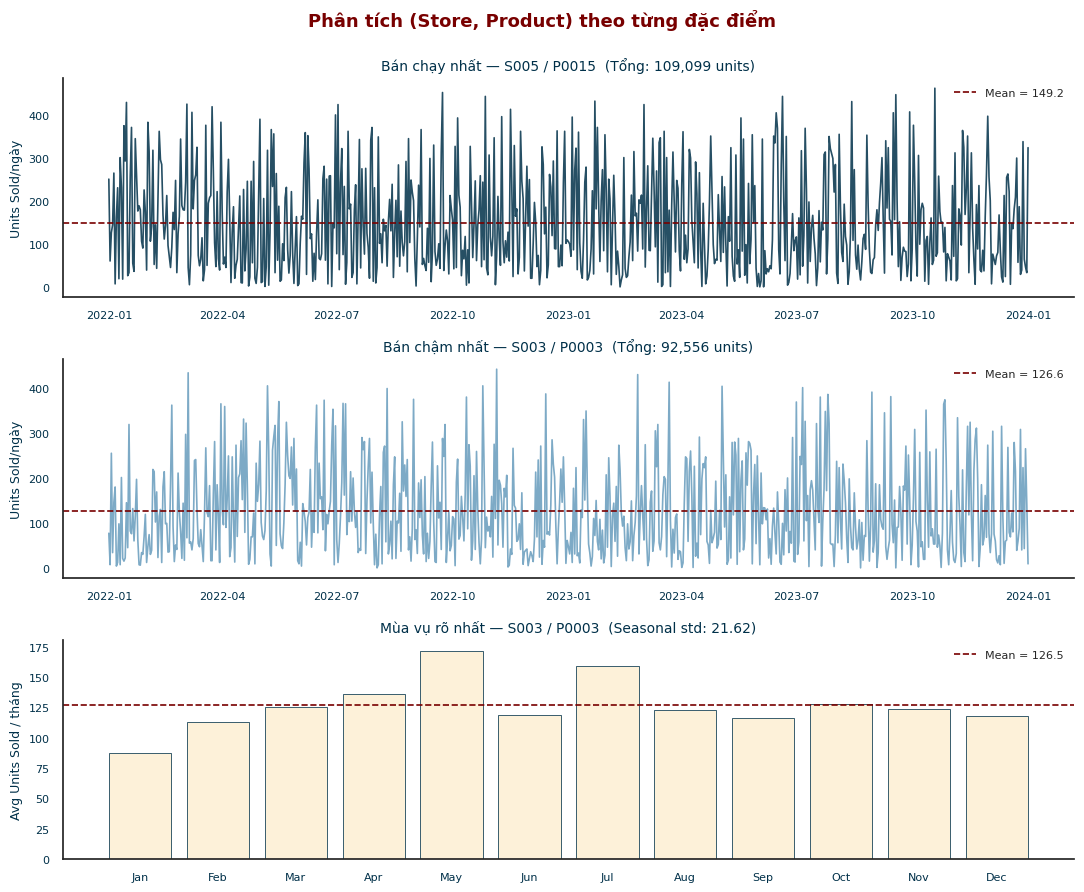

In [11]:
# ── 7. Plot ────────────────────────────────────────────────
palette = {
    "red_dark": "#780000",
    "red": "#C1121F",
    "cream": "#FDF0D5",
    "navy": "#003049",
    "blue": "#669BBC",
}

sns.set_theme(style="white", font="DejaVu Sans")

fig, axes = plt.subplots(3, 1, figsize=(11, 9))   # kich thuoc nho lai
fig.patch.set_facecolor("white")
fig.suptitle('Phân tích (Store, Product) theo từng đặc điểm',
             fontsize=13, fontweight="bold", color=palette["red_dark"], y=0.99)

# Plot 1: Ban chay - navy
axes[0].set_facecolor("white")
axes[0].plot(ts_best['Date'], ts_best['Units Sold'],
             color=palette["navy"], lw=1.2, alpha=0.85)
axes[0].axhline(ts_best['Units Sold'].mean(), color=palette["red_dark"],
                linestyle='--', lw=1.2, label=f'Mean = {ts_best["Units Sold"].mean():.1f}')
axes[0].set_title(f'Bán chạy nhất — {best_seller["Store ID"]} / {best_seller["Product ID"]}  '
                  f'(Tổng: {best_seller["total"]:,.0f} units)',
                  fontsize=10, color=palette["navy"])
axes[0].set_ylabel('Units Sold/ngày', fontsize=9, color=palette["navy"])
axes[0].tick_params(labelsize=8, colors=palette["navy"])
axes[0].legend(fontsize=8, frameon=False)
sns.despine(ax=axes[0])

# Plot 2: Ban cham - blue
axes[1].set_facecolor("white")
axes[1].plot(ts_slow['Date'], ts_slow['Units Sold'],
             color=palette["blue"], lw=1.2, alpha=0.85)
axes[1].axhline(ts_slow['Units Sold'].mean(), color=palette["red_dark"],
                linestyle='--', lw=1.2, label=f'Mean = {ts_slow["Units Sold"].mean():.1f}')
axes[1].set_title(f'Bán chậm nhất — {slow_seller["Store ID"]} / {slow_seller["Product ID"]}  '
                  f'(Tổng: {slow_seller["total"]:,.0f} units)',
                  fontsize=10, color=palette["navy"])
axes[1].set_ylabel('Units Sold/ngày', fontsize=9, color=palette["navy"])
axes[1].tick_params(labelsize=8, colors=palette["navy"])
axes[1].legend(fontsize=8, frameon=False)
sns.despine(ax=axes[1])

# Plot 3: Mua vu (monthly average) - red
axes[2].set_facecolor("white")
axes[2].bar(month_avg.index, month_avg.values,
            color=palette["cream"], edgecolor=palette["navy"], linewidth=0.6, alpha=0.9)
axes[2].set_xticks(range(1, 13))
axes[2].set_xticklabels(month_names)
axes[2].axhline(month_avg.mean(), color=palette["red_dark"],
                linestyle='--', lw=1.2, label=f'Mean = {month_avg.mean():.1f}')
axes[2].set_title(f'Mùa vụ rõ nhất — {most_seasonal["Store ID"]} / {most_seasonal["Product ID"]}  '
                  f'(Seasonal std: {most_seasonal["seasonal_std"]:.2f})',
                  fontsize=10, color=palette["navy"])
axes[2].set_ylabel('Avg Units Sold / tháng', fontsize=9, color=palette["navy"])
axes[2].tick_params(labelsize=8, colors=palette["navy"])
axes[2].legend(fontsize=8, frameon=False)
sns.despine(ax=axes[2])

plt.tight_layout()
plt.savefig('store_product_analysis.png', dpi=150, facecolor="white")
print('\nChart đã lưu: store_product_analysis.png')

In [12]:
# ── 8. In toàn bộ bảng xếp hạng ───────────────────────────
print('\n' + '='*55)
print('TOP 5 BÁN CHẠY NHẤT')
print(sp.sort_values('total', ascending=False)
      [['Store ID','Product ID','total','avg']].head(5).to_string(index=False))

print('\nTOP 5 BÁN CHẬM NHẤT')
print(sp.sort_values('total')
      [['Store ID','Product ID','total','avg']].head(5).to_string(index=False))

print('\nTOP 5 MÙA VỤ RÕ NHẤT (seasonal_std cao)')
print(sp.sort_values('seasonal_std', ascending=False)
      [['Store ID','Product ID','seasonal_std','avg']].head(5).to_string(index=False))


TOP 5 BÁN CHẠY NHẤT
Store ID Product ID  total        avg
    S005      P0015 109099 149.246238
    S003      P0013 107479 147.030096
    S002      P0001 105999 145.005472
    S005      P0003 105667 144.551300
    S003      P0005 105408 144.196990

TOP 5 BÁN CHẬM NHẤT
Store ID Product ID  total        avg
    S003      P0003  92556 126.615595
    S001      P0012  93854 128.391245
    S004      P0018  94023 128.622435
    S002      P0002  94143 128.786594
    S002      P0008  94225 128.898769

TOP 5 MÙA VỤ RÕ NHẤT (seasonal_std cao)
Store ID Product ID  seasonal_std        avg
    S003      P0003     21.623121 126.615595
    S005      P0017     21.023849 137.288646
    S003      P0019     20.945969 142.987688
    S004      P0001     18.767378 138.536252
    S003      P0010     17.762091 136.008208


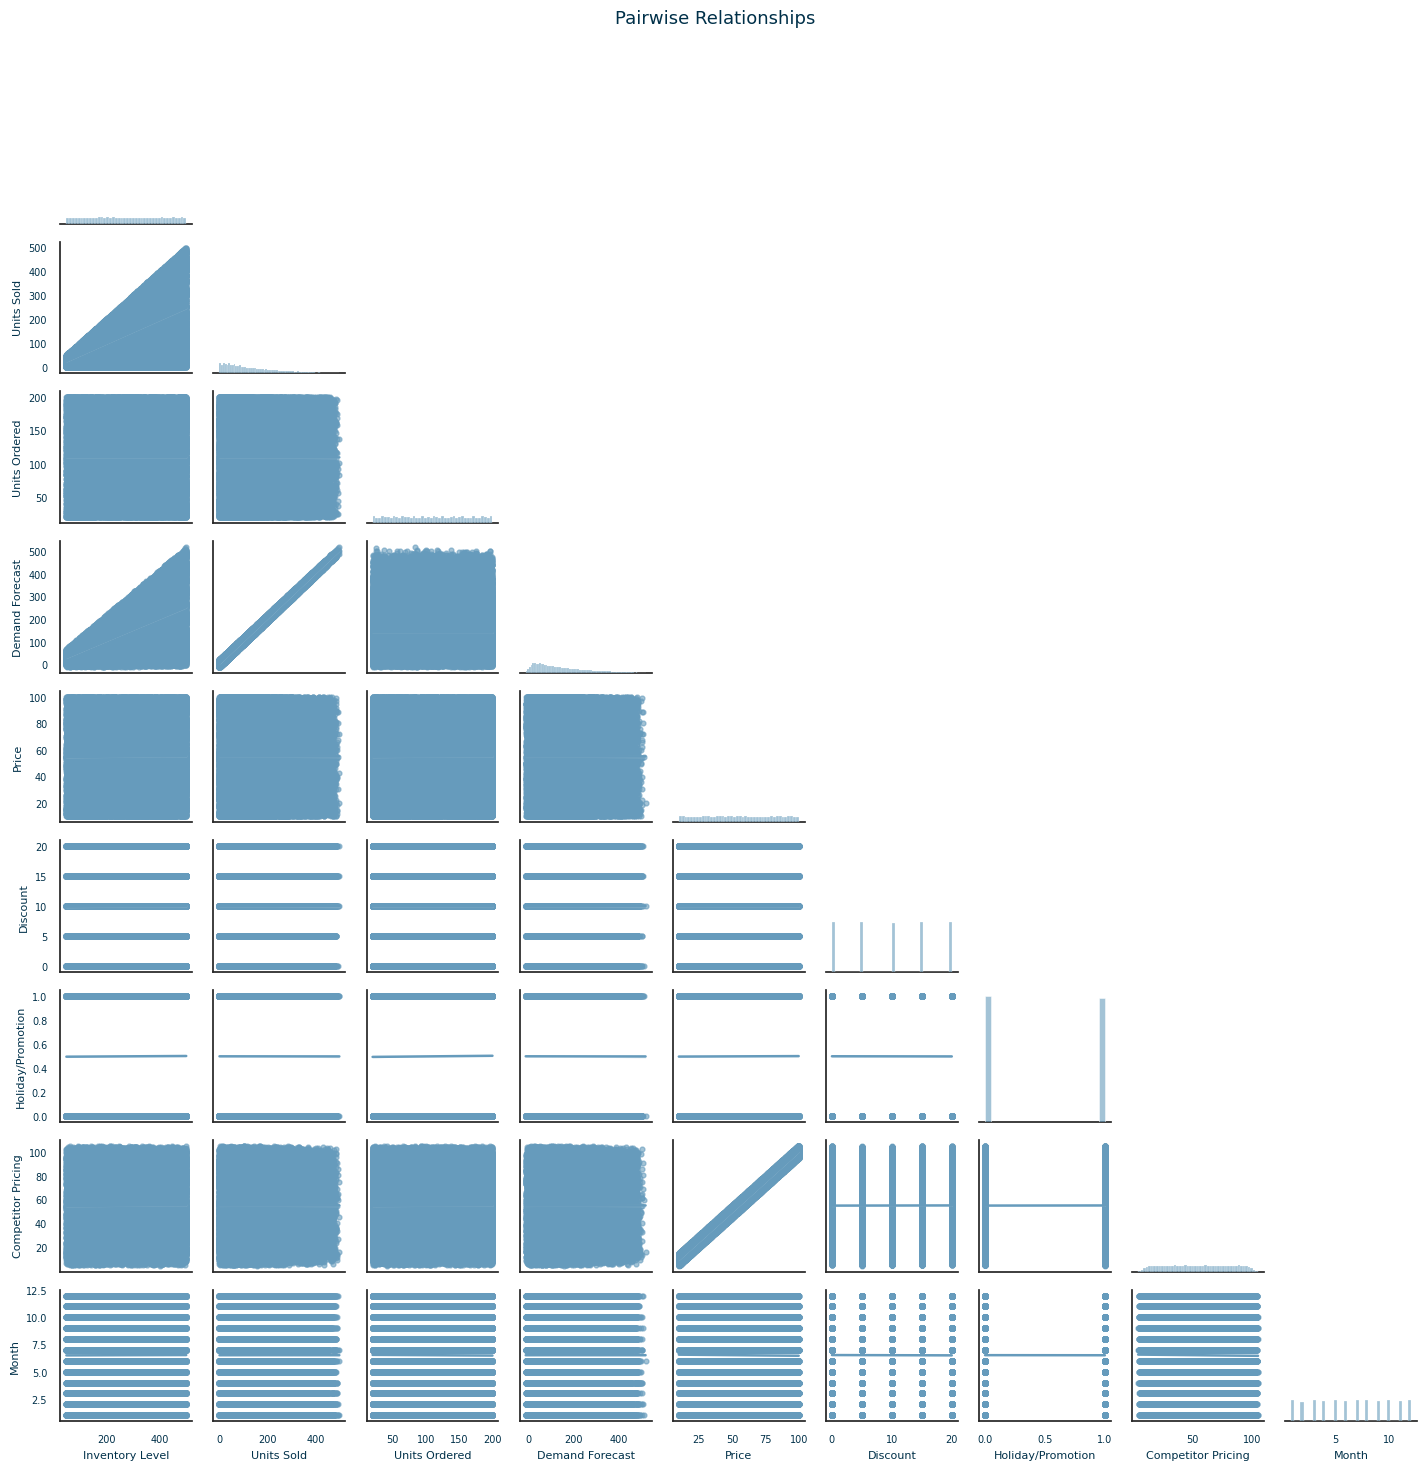

In [13]:
palette = {
    "red_dark": "#780000",
    "red": "#C1121F",
    "cream": "#FDF0D5",
    "navy": "#003049",
    "blue": "#669BBC",
}

sns.set_theme(style="white", font="DejaVu Sans")

g = sns.pairplot(
    df,
    kind="reg",
    height=1.6,
    aspect=1,
    corner=True,
    plot_kws={
        "scatter_kws": {
            "s": 12,
            "alpha": 0.6,
            "color": palette["blue"],
        },
        "line_kws": {
            "color": palette["blue"],
            "linewidth": 1.8,
        },
    },
    diag_kws={
        "color": palette["blue"],
        "fill": True,
        "alpha": 0.6,
    },
)

# Nền trắng
g.figure.patch.set_facecolor("white")

for ax in g.axes.flatten():
    if ax is not None:
        ax.set_facecolor("white")
        ax.tick_params(labelsize=7, colors=palette["navy"])
        ax.xaxis.label.set_size(8)
        ax.yaxis.label.set_size(8)
        ax.xaxis.label.set_color(palette["navy"])
        ax.yaxis.label.set_color(palette["navy"])

g.figure.suptitle(
    "Pairwise Relationships",
    y=1.02,
    fontsize=13,
    color=palette["navy"],
)

plt.tight_layout()
plt.show()

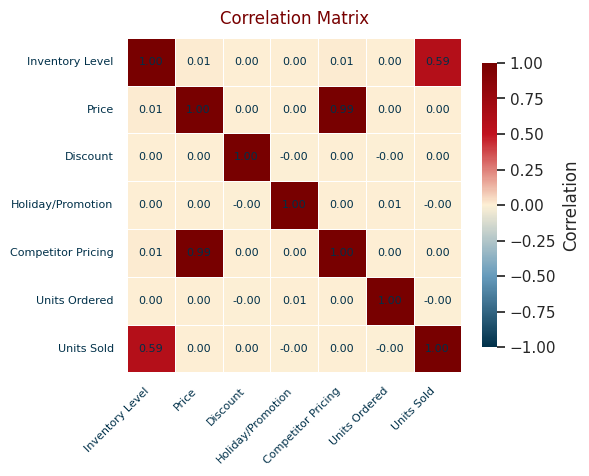

In [14]:
palette = {
    "red_dark": "#780000",
    "red": "#C1121F",
    "cream": "#FDF0D5",
    "navy": "#003049",
    "blue": "#669BBC",
}

# Custom colormap: xanh navy (am) -> kem (0) -> do dam (duong)
cmap = LinearSegmentedColormap.from_list(
    "fire_ice",
    [palette["navy"], palette["blue"], palette["cream"], palette["red"], palette["red_dark"]],
)

cols = ['Inventory Level', 'Price', 'Discount', 'Holiday/Promotion',
        'Competitor Pricing', 'Units Ordered', 'Units Sold']

corr = df[cols].corr()

fig, ax = plt.subplots(figsize=(6, 5))   # kich thuoc nho lai

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    annot_kws={"size": 8, "color": palette["navy"]},
    cmap=cmap,
    center=0,
    vmin=-1, vmax=1,
    linewidths=0.6,
    square=True,
    cbar_kws={"shrink": 0.8, "label": "Correlation"},
    ax=ax,
)

ax.set_facecolor(palette["cream"])
ax.set_title("Correlation Matrix", fontsize=12, color=palette["red_dark"], pad=10)
ax.tick_params(labelsize=8, colors=palette["navy"])
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")

plt.tight_layout()
plt.show()

/tmp/ipykernel_570/260155986.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


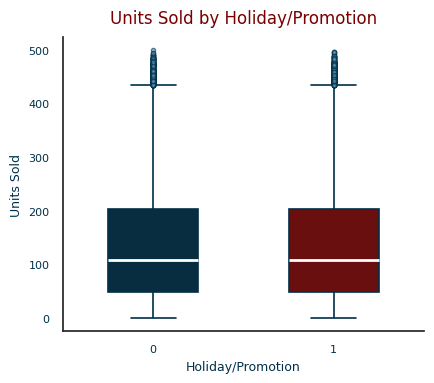

In [15]:
palette = {
    "red_dark": "#780000",
    "red": "#C1121F",
    "navy": "#003049",
    "blue": "#669BBC",
}

sns.set_theme(style="white", font="DejaVu Sans")

fig, ax = plt.subplots(figsize=(4.5, 4))   # kich thuoc nho lai

sns.boxplot(
    x=df['Holiday/Promotion'],
    y=df['Units Sold'],
    palette=[palette["navy"], palette["red_dark"]],   # 2 nhom: 0 vs 1
    width=0.5,
    linewidth=1.2,
    fliersize=3,
    boxprops={"edgecolor": palette["navy"]},
    whiskerprops={"color": palette["navy"]},
    capprops={"color": palette["navy"]},
    medianprops={"color": ("white"), "linewidth": 2},
    flierprops={"markerfacecolor": palette["blue"], "markeredgecolor": palette["navy"], "alpha": 0.6},
    ax=ax,
)

ax.set_facecolor("white")
fig.patch.set_facecolor("white")
ax.set_title("Units Sold by Holiday/Promotion", fontsize=12, color=palette["red_dark"], pad=10)
ax.set_xlabel("Holiday/Promotion", fontsize=9, color=palette["navy"])
ax.set_ylabel("Units Sold", fontsize=9, color=palette["navy"])
ax.tick_params(labelsize=8, colors=palette["navy"])
sns.despine(ax=ax)

plt.tight_layout()
plt.show()

/tmp/ipykernel_570/3237246935.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


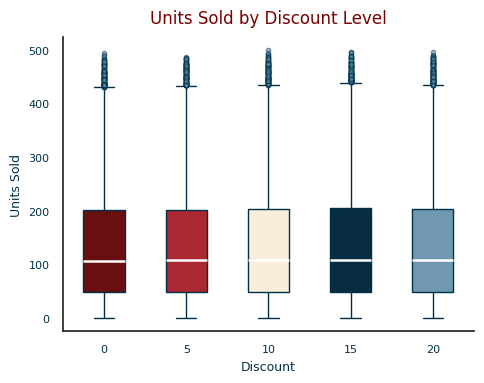

In [16]:
palette = {
    "red_dark": "#780000",
    "red": "#C1121F",
    "cream": "#FDF0D5",
    "navy": "#003049",
    "blue": "#669BBC",
}

sns.set_theme(style="white", font="DejaVu Sans")

# 5 mau cho 5 muc Discount
box_colors = [
    palette["red_dark"],
    palette["red"],
    palette["cream"],
    palette["navy"],
    palette["blue"],
]

fig, ax = plt.subplots(figsize=(5, 4))

sns.boxplot(
    x=df["Discount"],
    y=df["Units Sold"],
    palette=box_colors,
    width=0.5,
    linewidth=1.0,
    fliersize=3,
    boxprops={"edgecolor": palette["navy"]},
    whiskerprops={"color": palette["navy"]},
    capprops={"color": palette["navy"]},
    medianprops={"color": ("white"), "linewidth": 1.8},
    flierprops={
        "markerfacecolor": palette["blue"],
        "markeredgecolor": palette["navy"],
        "alpha": 0.5,
    },
    ax=ax,
)

ax.set_facecolor("white")
fig.patch.set_facecolor("white")

ax.set_title(
    "Units Sold by Discount Level",
    fontsize=12,
    color=palette["red_dark"],
    pad=10,
)

ax.set_xlabel("Discount", fontsize=9, color=palette["navy"])
ax.set_ylabel("Units Sold", fontsize=9, color=palette["navy"])
ax.tick_params(labelsize=8, colors=palette["navy"])

sns.despine(ax=ax)

plt.tight_layout()
plt.show()

/tmp/ipykernel_570/2297075671.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


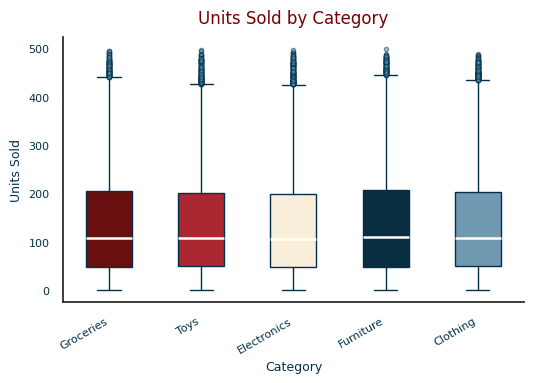

In [17]:
palette = {
    "red_dark": "#780000",   # Gochujang Red
    "red": "#C1121F",        # Crimson Blaze
    "cream": "#FDF0D5",      # Cream
    "navy": "#003049",       # Cosmos Blue
    "blue": "#669BBC",       # Blue Marble
}

sns.set_theme(style="white", font="DejaVu Sans")

# 5 mau cho 5 category
box_colors = [
    palette["red_dark"],
    palette["red"],
    palette["cream"],
    palette["navy"],
    palette["blue"],
]

fig, ax = plt.subplots(figsize=(5.5, 4))

sns.boxplot(
    x=df["Category"],
    y=df["Units Sold"],
    palette=box_colors,
    width=0.5,
    linewidth=1.0,
    fliersize=3,
    boxprops={"edgecolor": palette["navy"]},
    whiskerprops={"color": palette["navy"]},
    capprops={"color": palette["navy"]},
    medianprops={"color": ("white"), "linewidth": 1.8},
    flierprops={
        "markerfacecolor": palette["blue"],
        "markeredgecolor": palette["navy"],
        "alpha": 0.5,
    },
    ax=ax,
)

ax.set_facecolor("white")
fig.patch.set_facecolor("white")

ax.set_title(
    "Units Sold by Category",
    fontsize=12,
    color=palette["red_dark"],
    pad=10,
)

ax.set_xlabel("Category", fontsize=9, color=palette["navy"])
ax.set_ylabel("Units Sold", fontsize=9, color=palette["navy"])

ax.tick_params(labelsize=8, colors=palette["navy"])
plt.setp(ax.get_xticklabels(), rotation=30, ha="right")

sns.despine(ax=ax)

plt.tight_layout()
plt.show()

/tmp/ipykernel_570/858359657.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


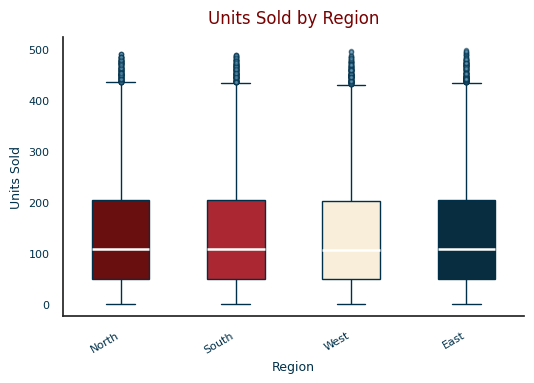

In [18]:
palette = {
    "red_dark": "#780000",   # Gochujang Red
    "red": "#C1121F",        # Crimson Blaze
    "cream": "#FDF0D5",      # Cream
    "navy": "#003049",       # Cosmos Blue
    "blue": "#669BBC",       # Blue Marble
}

sns.set_theme(style="white", font="DejaVu Sans")

# 5 mau cho 5 category
box_colors = [
    palette["red_dark"],
    palette["red"],
    palette["cream"],
    palette["navy"],
    palette["blue"],
]

# Cat box_colors theo dung so luong category thuc te cua 'Region'
# (fix: truoc day dung cung 5 mau cho moi cot, du cot co it hon 5 gia tri)
n_cat = df['Region'].nunique()
box_colors_used = box_colors[:n_cat]

fig, ax = plt.subplots(figsize=(5.5, 4))

sns.boxplot(
    x=df['Region'],
    y=df["Units Sold"],
    palette=box_colors_used,
    width=0.5,
    linewidth=1.0,
    fliersize=3,
    boxprops={"edgecolor": palette["navy"]},
    whiskerprops={"color": palette["navy"]},
    capprops={"color": palette["navy"]},
    medianprops={"color": ("white"), "linewidth": 1.8},
    flierprops={
        "markerfacecolor": palette["blue"],
        "markeredgecolor": palette["navy"],
        "alpha": 0.5,
    },
    ax=ax,
)

ax.set_facecolor("white")
fig.patch.set_facecolor("white")

ax.set_title(
    "Units Sold by Region",
    fontsize=12,
    color=palette["red_dark"],
    pad=10,
)

ax.set_xlabel("Region", fontsize=9, color=palette["navy"])
ax.set_ylabel("Units Sold", fontsize=9, color=palette["navy"])

ax.tick_params(labelsize=8, colors=palette["navy"])
plt.setp(ax.get_xticklabels(), rotation=30, ha="right")

sns.despine(ax=ax)

plt.tight_layout()
plt.show()

/tmp/ipykernel_570/588228005.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


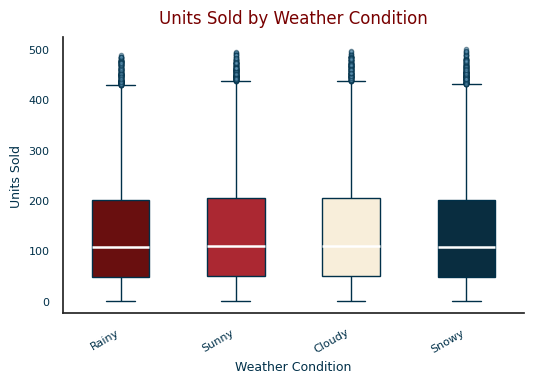

In [19]:
palette = {
    "red_dark": "#780000",   # Gochujang Red
    "red": "#C1121F",        # Crimson Blaze
    "cream": "#FDF0D5",      # Cream
    "navy": "#003049",       # Cosmos Blue
    "blue": "#669BBC",       # Blue Marble
}

sns.set_theme(style="white", font="DejaVu Sans")

# 5 mau cho 5 category
box_colors = [
    palette["red_dark"],
    palette["red"],
    palette["cream"],
    palette["navy"],
    palette["blue"],
]

# Cat box_colors theo dung so luong category thuc te cua 'Weather Condition'
# (fix: truoc day dung cung 5 mau cho moi cot, du cot co it hon 5 gia tri)
n_cat = df['Weather Condition'].nunique()
box_colors_used = box_colors[:n_cat]

fig, ax = plt.subplots(figsize=(5.5, 4))

sns.boxplot(
    x=df['Weather Condition'],
    y=df["Units Sold"],
    palette=box_colors_used,
    width=0.5,
    linewidth=1.0,
    fliersize=3,
    boxprops={"edgecolor": palette["navy"]},
    whiskerprops={"color": palette["navy"]},
    capprops={"color": palette["navy"]},
    medianprops={"color": ("white"), "linewidth": 1.8},
    flierprops={
        "markerfacecolor": palette["blue"],
        "markeredgecolor": palette["navy"],
        "alpha": 0.5,
    },
    ax=ax,
)

ax.set_facecolor("white")
fig.patch.set_facecolor("white")

ax.set_title(
    "Units Sold by Weather Condition",
    fontsize=12,
    color=palette["red_dark"],
    pad=10,
)

ax.set_xlabel("Weather Condition", fontsize=9, color=palette["navy"])
ax.set_ylabel("Units Sold", fontsize=9, color=palette["navy"])

ax.tick_params(labelsize=8, colors=palette["navy"])
plt.setp(ax.get_xticklabels(), rotation=30, ha="right")

sns.despine(ax=ax)

plt.tight_layout()
plt.show()

/tmp/ipykernel_570/3057548917.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


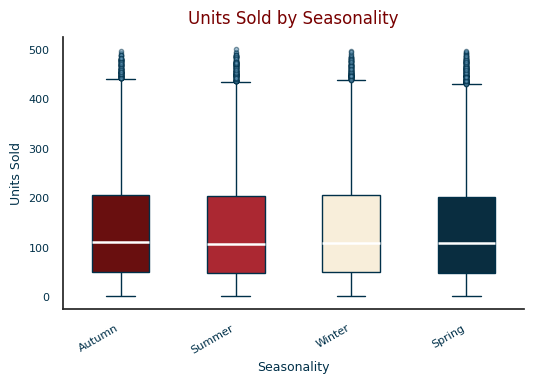

In [20]:
palette = {
    "red_dark": "#780000",   # Gochujang Red
    "red": "#C1121F",        # Crimson Blaze
    "cream": "#FDF0D5",      # Cream
    "navy": "#003049",       # Cosmos Blue
    "blue": "#669BBC",       # Blue Marble
}

sns.set_theme(style="white", font="DejaVu Sans")

# 5 mau cho 5 category
box_colors = [
    palette["red_dark"],
    palette["red"],
    palette["cream"],
    palette["navy"],
    palette["blue"],
]

# Cat box_colors theo dung so luong category thuc te cua 'Seasonality'
# (fix: truoc day dung cung 5 mau cho moi cot, du cot co it hon 5 gia tri)
n_cat = df['Seasonality'].nunique()
box_colors_used = box_colors[:n_cat]

fig, ax = plt.subplots(figsize=(5.5, 4))

sns.boxplot(
    x=df['Seasonality'],
    y=df["Units Sold"],
    palette=box_colors_used,
    width=0.5,
    linewidth=1.0,
    fliersize=3,
    boxprops={"edgecolor": palette["navy"]},
    whiskerprops={"color": palette["navy"]},
    capprops={"color": palette["navy"]},
    medianprops={"color": ("white"), "linewidth": 1.8},
    flierprops={
        "markerfacecolor": palette["blue"],
        "markeredgecolor": palette["navy"],
        "alpha": 0.5,
    },
    ax=ax,
)

ax.set_facecolor("white")
fig.patch.set_facecolor("white")

ax.set_title(
    "Units Sold by Seasonality",
    fontsize=12,
    color=palette["red_dark"],
    pad=10,
)

ax.set_xlabel("Seasonality", fontsize=9, color=palette["navy"])
ax.set_ylabel("Units Sold", fontsize=9, color=palette["navy"])

ax.tick_params(labelsize=8, colors=palette["navy"])
plt.setp(ax.get_xticklabels(), rotation=30, ha="right")

sns.despine(ax=ax)

plt.tight_layout()
plt.show()

#2. Tiền xử lý dữ liệu

In [21]:
data = df.copy(deep=True)

In [22]:
# encode các cột cần sử dụng bằng one-hot encoder
_enc = OneHotEncoder(sparse_output=False)
_enc.fit(data[['Category', 'Region', 'Weather Condition', 'Seasonality']])
_transformed = pd.DataFrame(_enc.transform(data[['Category', 'Region', 'Weather Condition', 'Seasonality']]),
                            columns=_enc.get_feature_names_out(),
                            index=data.index  # giữ đúng index để concat không bị lệch dòng
)

_transformed

,Category_Clothing,Category_Electronics,Category_Furniture,Category_Groceries,Category_Toys,Region_East,Region_North,Region_South,Region_West,Weather Condition_Cloudy,Weather Condition_Rainy,Weather Condition_Snowy,Weather Condition_Sunny,Seasonality_Autumn,Seasonality_Spring,Seasonality_Summer,Seasonality_Winter
0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
3,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
4,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
73095,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
73096,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
73097,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
73098,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0


In [23]:
# nối ngang dataframe vừa tạo phía trên và các cột số; đây sẽ là dataframe input cho mô hình
X = pd.concat([_transformed, data[['Inventory Level','Price','Discount','Holiday/Promotion','Units Ordered']]], axis=1)
# chú ý, axis=1 sẽ nối ngang, axis=0 (mặc định) sẽ nối dòng

# FIX: dùng Series 1D (1 cặp ngoặc) thay vì DataFrame 2D (2 cặp ngoặc) để tránh
# sklearn DataConversionWarning ("A column-vector y was passed when a 1d array was expected")
y = data['Units Sold']

# Lưu ý: X ở đây CHƯA scale (raw) - việc scale sẽ làm SAU khi chia train/test (xem cell dưới)
# để tránh rò rỉ dữ liệu (data leakage) từ test set vào bước tiền xử lý.


In [24]:
X

,Category_Clothing,Category_Electronics,Category_Furniture,Category_Groceries,Category_Toys,Region_East,Region_North,Region_South,Region_West,Weather Condition_Cloudy,...,Weather Condition_Sunny,Seasonality_Autumn,Seasonality_Spring,Seasonality_Summer,Seasonality_Winter,Inventory Level,Price,Discount,Holiday/Promotion,Units Ordered
0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,231,33.50,20,0,55
1,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,...,1.0,1.0,0.0,0.0,0.0,204,63.01,20,0,66
2,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,...,1.0,0.0,0.0,1.0,0.0,102,27.99,10,1,51
3,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,0.0,1.0,0.0,0.0,0.0,469,32.72,10,1,164
4,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,1.0,0.0,166,73.64,0,0,135
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
73095,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,96,73.73,20,0,127
73096,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,0.0,1.0,0.0,0.0,0.0,313,82.57,10,0,101
73097,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,1.0,278,11.11,10,0,151
73098,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,374,53.14,20,0,21


In [25]:
y

,Units Sold
0,127
1,150
2,65
3,61
4,14
...,...
73095,8
73096,51
73097,36
73098,264


In [26]:
# FIX (rò rỉ dữ liệu #1 - scaling leakage):
# Trước đây code fit StandardScaler trên TOÀN BỘ X rồi mới chia train/test,
# nghĩa là mean/std dùng để scale đã "nhìn thấy" cả các dòng sau này rơi vào test set.
# -> Sửa: chia train/test TRƯỚC, fit scaler CHỈ trên train, rồi transform test.
#
# FIX (rò rỉ dữ liệu #2 - random split trên time-series):
# Trước đây dùng train_test_split(..., random_state=42) chia NGẪU NHIÊN trên dữ liệu
# vốn có tính tự tương quan theo thời gian (nhiều dòng cùng Store-Product ở các ngày
# liền kề) -> model "nhìn trộm" được các ngày lân cận của chính chuỗi đó trong lúc train
# -> kết quả test bị lạc quan hơn thực tế.
# -> Sửa: chia THEO THỜI GIAN (giống cách tiếp cận đúng đã dùng ở Mục 3.3 "có biến thời
# gian" bên dưới), dùng chung 1 mốc split_date, thống nhất cho cả Linear Regression,
# Decision Tree và Random Forest (bản gốc) để so sánh công bằng với nhau.

split_date = data['Date'].quantile(0.8)

train_mask = data['Date'] <= split_date
test_mask  = data['Date'] > split_date

X_train_raw, X_test_raw = X[train_mask], X[test_mask]
y_train, y_test = y[train_mask], y[test_mask]

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw)
X_test = scaler.transform(X_test_raw)   # QUAN TRỌNG: chỉ transform, KHÔNG fit lại trên test

print(f"Train: {len(X_train)} dòng | Test: {len(X_test)} dòng")
print(f"Ngày chia (80% quantile): {split_date}")


Train: 58500 dòng | Test: 14600 dòng
Ngày chia (80% quantile): 2023-08-08 00:00:00


In [27]:
X_train


array([[-0.50133512, -0.49564249, -0.50056083, ...,  1.40842026,
        -0.99662109, -1.05127729],
       [-0.50133512, -0.49564249, -0.50056083, ...,  1.40842026,
        -0.99662109, -0.84098053],
       [-0.50133512, -0.49564249, -0.50056083, ..., -0.00296753,
         1.00339036, -1.12774884],
       ...,
       [ 1.99467376, -0.49564249, -0.50056083, ...,  0.70272636,
         1.00339036, -0.40126911],
       [-0.50133512, -0.49564249, -0.50056083, ...,  1.40842026,
         1.00339036, -0.55421221],
       [-0.50133512, -0.49564249, -0.50056083, ..., -1.41435533,
        -0.99662109, -0.53509432]])

#3. Xây dựng mô hình



##3.0 Định nghĩa hàm đánh giá mô hình

In [28]:
# Ham danh gia mo hinh dung chung cho Linear Regression, Decision Tree, Random Forest
# Ve 3 loai bieu do: Actual vs Predicted | Residual Plot | Residual Distribution
# Ve rieng Train va Test de phat hien overfitting

palette = {
    "red_dark": "#780000",
    "red": "#C1121F",
    "cream": "#FDF0D5",
    "navy": "#003049",
    "blue": "#669BBC",
}

sns.set_theme(style="white", font="DejaVu Sans")


def plot_model_evaluation(model_name, y_train, y_pred_train, y_test, y_pred_test):
    y_train = np.asarray(y_train).ravel()
    y_pred_train = np.asarray(y_pred_train).ravel()
    y_test = np.asarray(y_test).ravel()
    y_pred_test = np.asarray(y_pred_test).ravel()

    resid_train = y_train - y_pred_train
    resid_test = y_test - y_pred_test

    fig, axes = plt.subplots(3, 2, figsize=(11, 12))
    fig.patch.set_facecolor("white")
    fig.suptitle(f"Model Evaluation - {model_name}", fontsize=14, fontweight="bold",
                 color=palette["red_dark"], y=0.995)

    splits = [
        ("Train", y_train, y_pred_train, resid_train, palette["navy"]),
        ("Test", y_test, y_pred_test, resid_test, palette["red_dark"]),
    ]

    for col, (label, y_true, y_pred, resid, color) in enumerate(splits):

        # --- Row 1: Actual vs Predicted ---
        ax = axes[0, col]
        ax.set_facecolor("white")
        ax.scatter(y_true, y_pred, color=color, edgecolor=palette["navy"], s=16, alpha=0.5)
        lims = [min(y_true.min(), y_pred.min()), max(y_true.max(), y_pred.max())]
        ax.plot(lims, lims, color=palette["red"], linestyle="--", linewidth=1.5, label="y = x")
        ax.set_xlim(lims)
        ax.set_ylim(lims)
        r2 = r2_score(y_true, y_pred)
        ax.text(0.05, 0.95, f"R2 = {r2:.4f}", transform=ax.transAxes, fontsize=9, va="top",
                color=palette["navy"],
                bbox=dict(boxstyle="round", facecolor=palette["cream"], edgecolor=palette["navy"]))
        ax.set_title(f"Actual vs Predicted - {label}", fontsize=10, fontweight="bold", color=palette["navy"])
        ax.set_xlabel("Actual", fontsize=9, color=palette["navy"])
        ax.set_ylabel("Predicted", fontsize=9, color=palette["navy"])
        ax.tick_params(labelsize=8, colors=palette["navy"])
        ax.legend(fontsize=8, frameon=False)
        sns.despine(ax=ax)

        # --- Row 2: Residual plot (predicted vs residual) ---
        ax = axes[1, col]
        ax.set_facecolor("white")
        ax.scatter(y_pred, resid, color=color, edgecolor=palette["navy"], s=16, alpha=0.5)
        ax.axhline(0, color=palette["red"], linestyle="--", linewidth=1.5)
        ax.set_title(f"Residual Plot - {label}", fontsize=10, fontweight="bold", color=palette["navy"])
        ax.set_xlabel("Predicted", fontsize=9, color=palette["navy"])
        ax.set_ylabel("Residual (Actual - Predicted)", fontsize=9, color=palette["navy"])
        ax.tick_params(labelsize=8, colors=palette["navy"])
        sns.despine(ax=ax)

        # --- Row 3: Residual distribution ---
        ax = axes[2, col]
        ax.set_facecolor("white")
        sns.histplot(resid, kde=True, color=color, edgecolor=palette["navy"], alpha=0.6, ax=ax)
        ax.axvline(0, color=palette["red"], linestyle="--", linewidth=1.5)
        ax.set_title(f"Residual Distribution - {label}", fontsize=10, fontweight="bold", color=palette["navy"])
        ax.set_xlabel("Residual", fontsize=9, color=palette["navy"])
        ax.set_ylabel("Frequency", fontsize=9, color=palette["navy"])
        ax.tick_params(labelsize=8, colors=palette["navy"])
        sns.despine(ax=ax)

    plt.tight_layout(rect=[0, 0, 1, 0.97])
    plt.show()

In [29]:
# Danh sach luu metric cua tung model (MAE/RMSE/R2 tren tap test) de ve bar chart so sanh o cuoi notebook
model_comparison_data = []

## 3.1 Linear Regression

In [30]:
# Train/test đã được chia THEO THỜI GIAN và scale đúng cách (fit chỉ trên train)
# ở Mục 2 - Tiền xử lý dữ liệu (X_train, X_test, y_train, y_test).
# Dùng chung 1 bộ split này cho Linear Regression / Decision Tree / Random Forest (bản gốc)
# để đảm bảo so sánh công bằng giữa 3 model, và tránh rò rỉ dữ liệu do random split
# trên dữ liệu time-series (xem giải thích chi tiết ở Mục 2).


In [31]:
# train model trên tập train
_model = LinearRegression()
_model.fit(X=X_train, y=y_train)

LinearRegression()

In [32]:
# predict trên tập test, gán kết quả predict này là y_pred để tiện cho việc đánh giá model bên dưới
y_pred = _model.predict(X_test)

In [33]:
y_pred

array([233.60748605,  28.57134536, 215.75366613, ..., 138.53905311,
       185.11024358,  55.50256686])

In [34]:
r2_score(y_test, y_pred)

0.34419551425670947

In [35]:
mean_absolute_error(y_test, y_pred)

68.64625183835653

In [75]:
mean_squared_error(y_test, y_pred)

7745.163176524689

In [74]:
RMSE = np.sqrt(mean_squared_error(y_test, y_pred))
RMSE

np.float64(88.00660870937301)

In [37]:
mean_absolute_percentage_error(y_test, y_pred)

1865154931194831.8

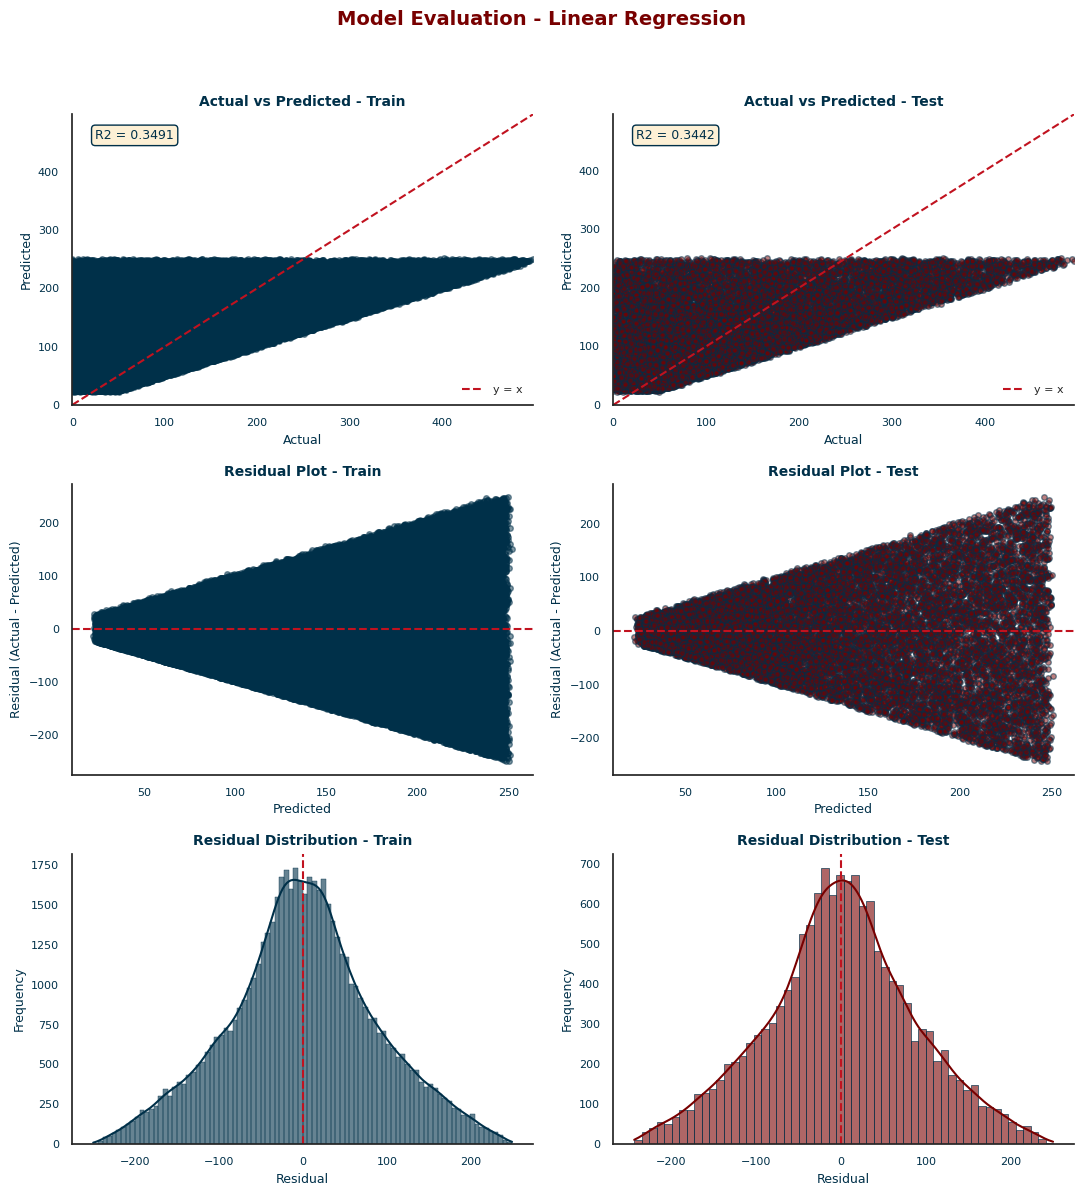

In [38]:
# Du doan tren tap train de danh gia overfitting (Linear Regression chua co buoc nay o tren)
y_pred_train = _model.predict(X_train)

# Ve dashboard danh gia: Actual vs Predicted, Residual Plot, Residual Distribution
plot_model_evaluation("Linear Regression", y_train, y_pred_train, y_test, y_pred)

In [39]:
# Luu metric cua Linear Regression de so sanh voi cac model khac o cuoi notebook
model_comparison_data.append({
    "Model": "Linear Regression",
    "MAE": mean_absolute_error(y_test, y_pred),
    "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
    "R2": r2_score(y_test, y_pred),
})

# Luu actual/predicted cua Linear Regression de ve chung 1 chart o Muc 4
actual_vs_predicted_data["Linear Regression"] = (
    np.asarray(y_test).ravel().copy(), np.asarray(y_pred).ravel().copy()
)

## 3.2 Decision Tree

In [40]:
# Train/test đã được chia THEO THỜI GIAN và scale đúng cách (fit chỉ trên train)
# ở Mục 2 - Tiền xử lý dữ liệu (X_train, X_test, y_train, y_test).
# Dùng chung 1 bộ split này cho Linear Regression / Decision Tree / Random Forest (bản gốc)
# để đảm bảo so sánh công bằng giữa 3 model, và tránh rò rỉ dữ liệu do random split
# trên dữ liệu time-series (xem giải thích chi tiết ở Mục 2).


In [41]:
# Khởi tạo Decision Tree Regression
dt_model = DecisionTreeRegressor(
    random_state=42,
    max_depth=5      # có thể thay đổi để tối ưu
)

# Train model
dt_model.fit(X_train, y_train)

DecisionTreeRegressor(max_depth=5, random_state=42)

In [42]:
# Dự đoán trên tập train
y_pred_train = dt_model.predict(X_train)

# Dự đoán trên tập test
y_pred_test = dt_model.predict(X_test)

In [43]:
r2_train = r2_score(y_train, y_pred_train)
r2_test = r2_score(y_test, y_pred_test)

mae_test = mean_absolute_error(y_test, y_pred_test)

mse_test = mean_squared_error(y_test, y_pred_test)

rmse_test = np.sqrt(mse_test)

mape_test = mean_absolute_percentage_error(y_test, y_pred_test)

In [44]:
print("Decision Tree Regression Performance")
print("-----------------------------------")

print(f"R² Train : {r2_train:.4f}")
print(f"R² Test  : {r2_test:.4f}")
print(f"Difference: {abs(r2_train-r2_test):.4f}")

print(f"MAE  : {mae_test:.4f}")
print(f"MSE  : {mse_test:.4f}")
print(f"RMSE : {rmse_test:.4f}")
print(f"MAPE : {mape_test:.4f}")

Decision Tree Regression Performance
-----------------------------------
R² Train : 0.3511
R² Test  : 0.3421
Difference: 0.0090
MAE  : 68.6998
MSE  : 7708.8745
RMSE : 87.8002
MAPE : 1851716747815666.7500


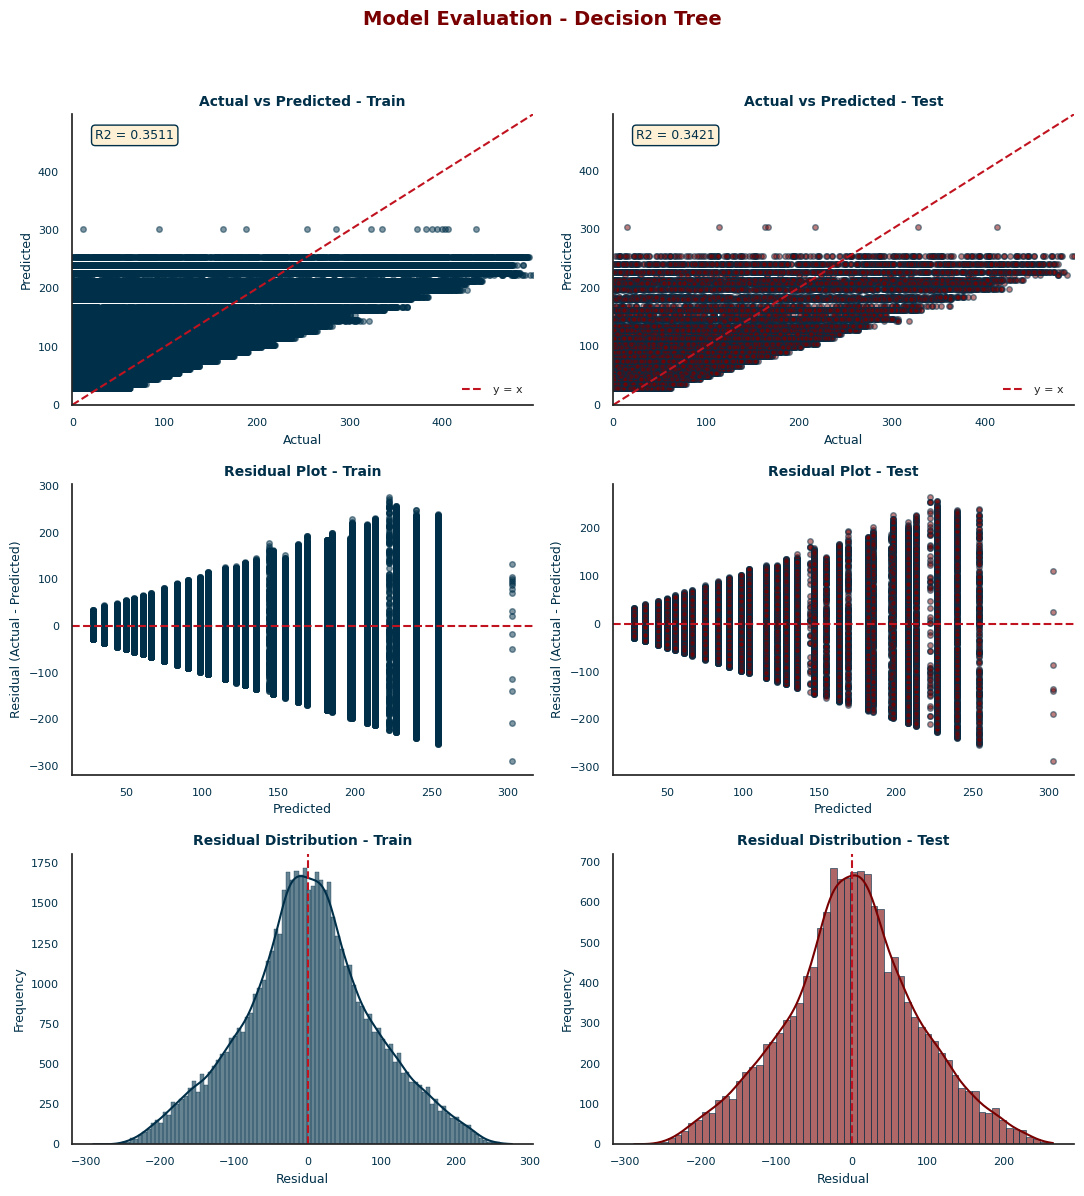

In [45]:
# Ve dashboard danh gia: Actual vs Predicted, Residual Plot, Residual Distribution
plot_model_evaluation("Decision Tree", y_train, y_pred_train, y_test, y_pred_test)

In [46]:
# Luu metric cua Decision Tree de so sanh voi cac model khac o cuoi notebook
model_comparison_data.append({
    "Model": "Decision Tree",
    "MAE": mae_test,
    "RMSE": rmse_test,
    "R2": r2_test,
})

# Luu actual/predicted cua Decision Tree de ve chung 1 chart o Muc 4
actual_vs_predicted_data["Decision Tree"] = (
    np.asarray(y_test).ravel().copy(), np.asarray(y_pred_test).ravel().copy()
)

##3.3 Random Forest

In [47]:
# Train/test đã được chia THEO THỜI GIAN và scale đúng cách (fit chỉ trên train)
# ở Mục 2 - Tiền xử lý dữ liệu (X_train, X_test, y_train, y_test).
# Dùng chung 1 bộ split này cho Linear Regression / Decision Tree / Random Forest (bản gốc)
# để đảm bảo so sánh công bằng giữa 3 model, và tránh rò rỉ dữ liệu do random split
# trên dữ liệu time-series (xem giải thích chi tiết ở Mục 2).


In [48]:
# Khởi tạo Random Forest Regression
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=10,
    random_state=42
)

# Train model
rf_model.fit(X_train, y_train)

RandomForestRegressor(max_depth=10, random_state=42)

In [49]:
# Dự đoán trên tập train
y_pred_train = rf_model.predict(X_train)

# Dự đoán trên tập test
y_pred_test = rf_model.predict(X_test)

In [50]:
# R²
r2_train = r2_score(y_train, y_pred_train)
r2_test = r2_score(y_test, y_pred_test)

# MAE
mae_test = mean_absolute_error(y_test, y_pred_test)

# MSE
mse_test = mean_squared_error(y_test, y_pred_test)

# RMSE
rmse_test = np.sqrt(mse_test)

# MAPE
mape_test = mean_absolute_percentage_error(y_test, y_pred_test)

In [51]:
print("Random Forest Regression Performance")
print("------------------------------------")

print(f"R² Train : {r2_train:.4f}")
print(f"R² Test  : {r2_test:.4f}")
print(f"Chênh lệch: {abs(r2_train-r2_test):.4f}")

print(f"MAE  : {mae_test:.4f}")
print(f"MSE  : {mse_test:.4f}")
print(f"RMSE : {rmse_test:.4f}")
print(f"MAPE : {mape_test:.4f}")

Random Forest Regression Performance
------------------------------------
R² Train : 0.4154
R² Test  : 0.3396
Chênh lệch: 0.0757
MAE  : 68.8408
MSE  : 7737.5895
RMSE : 87.9636
MAPE : 1855307625024009.7500


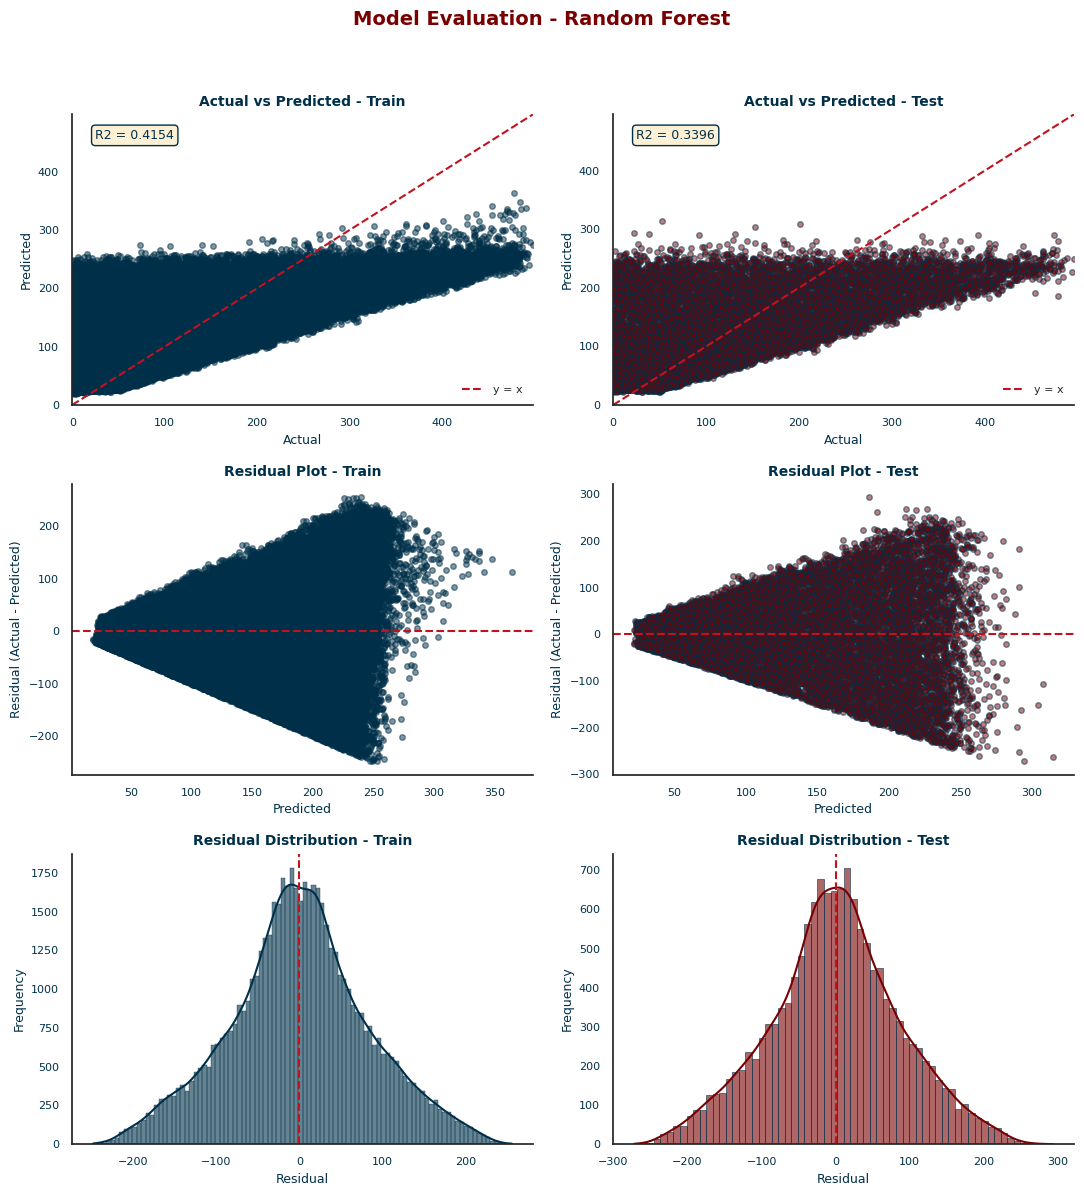

In [52]:
# Ve dashboard danh gia: Actual vs Predicted, Residual Plot, Residual Distribution
plot_model_evaluation("Random Forest", y_train, y_pred_train, y_test, y_pred_test)

In [53]:
# Luu metric cua Random Forest (ban goc, khong co lag/date) de so sanh o cuoi notebook
model_comparison_data.append({
    "Model": "Random Forest",
    "MAE": mae_test,
    "RMSE": rmse_test,
    "R2": r2_test,
})

# Luu actual/predicted cua Random Forest (ban goc) de ve chung 1 chart o Muc 4
actual_vs_predicted_data["Random Forest"] = (
    np.asarray(y_test).ravel().copy(), np.asarray(y_pred_test).ravel().copy()
)

##3.3 Random Forest có biến thời gian

In [54]:
# Xử lý cột Date
data['Date'] = pd.to_datetime(data['Date'])

# Sắp xếp theo Store, Product, Date để đảm bảo lag/rolling tính đúng thứ tự thời gian
data = data.sort_values(['Store ID', 'Product ID', 'Date']).reset_index(drop=True)

# Tạo date-derived features
data['DayOfWeek'] = data['Date'].dt.dayofweek        # 0=Thứ 2 ... 6=Chủ nhật
data['Month'] = data['Date'].dt.month
data['IsWeekend'] = (data['DayOfWeek'] >= 5).astype(int)
data['DayOfMonth'] = data['Date'].dt.day

#Tạo lag & rolling features theo từng Store-Product
# groupby đảm bảo lag của P0001-S001 không bị lẫn với P0002-S001
group_cols = ['Store ID', 'Product ID']

data['lag_1'] = data.groupby(group_cols)['Units Sold'].shift(1)
data['lag_7'] = data.groupby(group_cols)['Units Sold'].shift(7)

data['rolling_mean_7'] = (
    data.groupby(group_cols)['Units Sold']
        .shift(1)  # shift(1) để tránh dùng chính giá trị hiện tại (leakage)
        .rolling(window=7)
        .mean()
)

data['rolling_mean_14'] = (
    data.groupby(group_cols)['Units Sold']
        .shift(1)
        .rolling(window=14)
        .mean()
)

# Loại bỏ các dòng đầu mỗi SKU bị NaN do chưa đủ lịch sử
data = data.dropna(subset=['lag_1', 'lag_7', 'rolling_mean_7', 'rolling_mean_14']).reset_index(drop=True)

print(f"Số dòng còn lại sau khi tạo lag features: {len(data)}")

# One-hot encode như code gốc
_enc = OneHotEncoder(sparse_output=False)
_enc.fit(data[['Category', 'Region', 'Weather Condition', 'Seasonality']])
_transformed = pd.DataFrame(
    _enc.transform(data[['Category', 'Region', 'Weather Condition', 'Seasonality']]),
    columns=_enc.get_feature_names_out(),
    index=data.index  # giữ đúng index để concat không bị lệch dòng
)

# Ghép toàn bộ feature
X = pd.concat([
    _transformed,
    data[[
        'Inventory Level', 'Price', 'Discount', 'Holiday/Promotion', 'Units Ordered',
        'DayOfWeek', 'Month', 'IsWeekend', 'DayOfMonth',
        'lag_1', 'lag_7', 'rolling_mean_7', 'rolling_mean_14'
    ]]
], axis=1)

y = data['Units Sold']

# Chia train/test theo THỜI GIAN (không random)
# Cách đơn giản: lấy mốc thời gian, ví dụ 80% đầu làm train
split_date = data['Date'].quantile(0.8)  # hoặc chỉ định 1 ngày cụ thể, VD: '2023-09-01'

train_mask = data['Date'] <= split_date
test_mask = data['Date'] > split_date

X_train_raw, X_test_raw = X[train_mask], X[test_mask]
y_train, y_test = y[train_mask], y[test_mask]

print(f"Train: {len(X_train_raw)} dòng | Test: {len(X_test_raw)} dòng")
print(f"Ngày chia: {split_date}")

# Scale (fit trên train, transform cả 2)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw)
X_test = scaler.transform(X_test_raw)  # QUAN TRỌNG: chỉ transform, không fit lại trên test

# Train model
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=10,
    random_state=42
)

rf_model.fit(X_train, y_train)

y_pred_train = rf_model.predict(X_train)
y_pred_test = rf_model.predict(X_test)

r2_train = r2_score(y_train, y_pred_train)
r2_test = r2_score(y_test, y_pred_test)
mae_test = mean_absolute_error(y_test, y_pred_test)
mse_test = mean_squared_error(y_test, y_pred_test)
rmse_test = np.sqrt(mse_test)
mape_test = mean_absolute_percentage_error(y_test, y_pred_test)

print(f"R² train: {r2_train:.4f} | R² test: {r2_test:.4f}")
print(f"MAE: {mae_test:.2f} | RMSE: {rmse_test:.2f} | MAPE: {mape_test:.2f}")

Số dòng còn lại sau khi tạo lag features: 71700
Train: 57400 dòng | Test: 14300 dòng
Ngày chia: 2023-08-11 00:00:00
R² train: 0.4261 | R² test: 0.3387
MAE: 68.88 | RMSE: 88.01 | MAPE: 1885369825566731.50


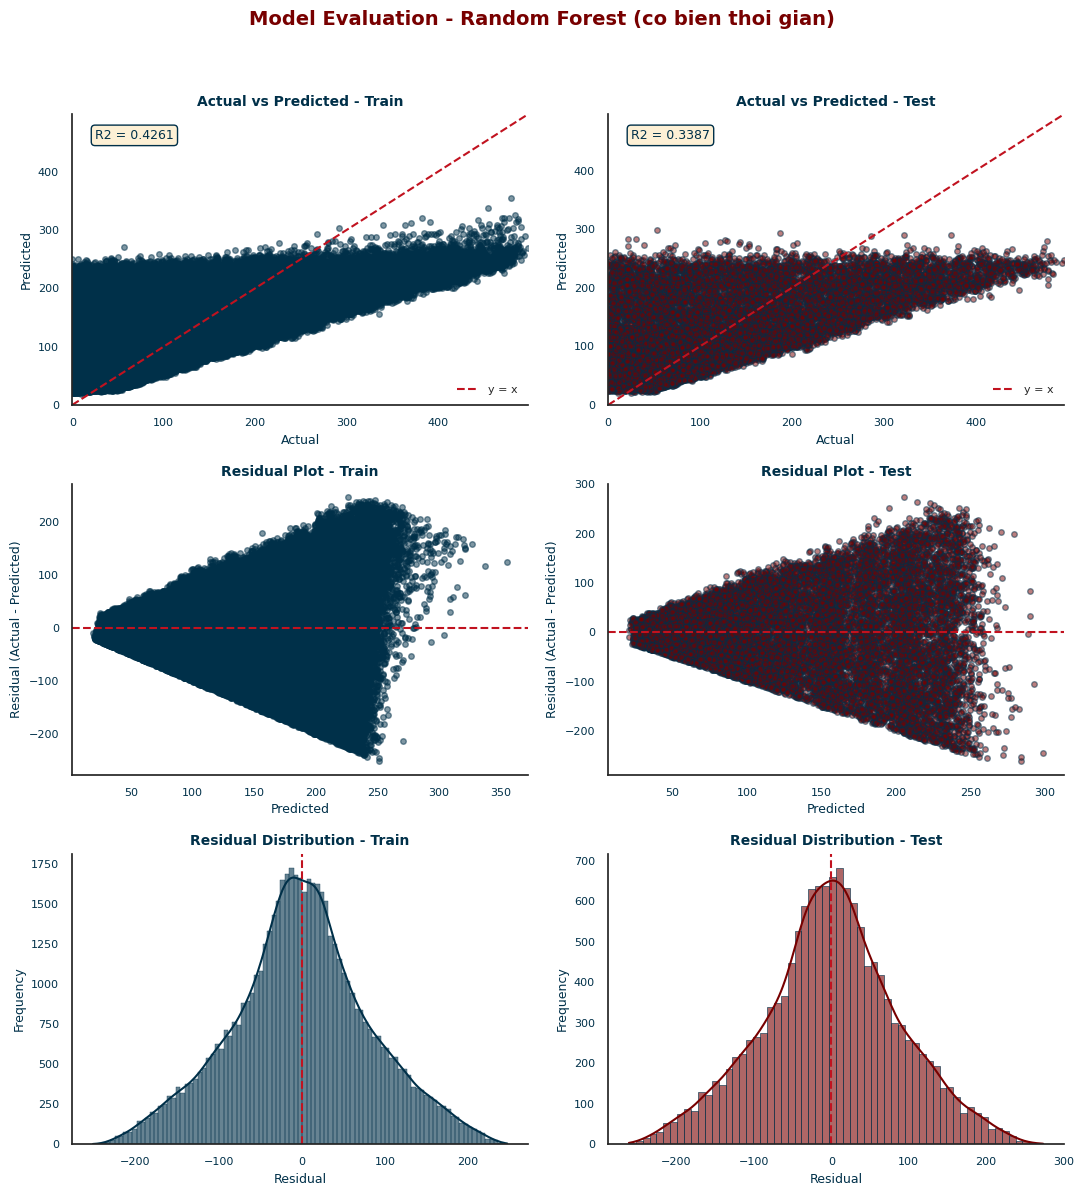

In [55]:
# Ve dashboard danh gia: Actual vs Predicted, Residual Plot, Residual Distribution
plot_model_evaluation("Random Forest (co bien thoi gian)", y_train, y_pred_train, y_test, y_pred_test)

In [56]:
# Luu metric cua Random Forest (co bien thoi gian) de so sanh o cuoi notebook
model_comparison_data.append({
    "Model": "Random Forest (co bien thoi gian)",
    "MAE": mae_test,
    "RMSE": rmse_test,
    "R2": r2_test,
})

# Luu actual/predicted cua Random Forest (co bien thoi gian) de ve chung 1 chart o Muc 4
actual_vs_predicted_data["Random Forest (co bien thoi gian)"] = (
    np.asarray(y_test).ravel().copy(), np.asarray(y_pred_test).ravel().copy()
)

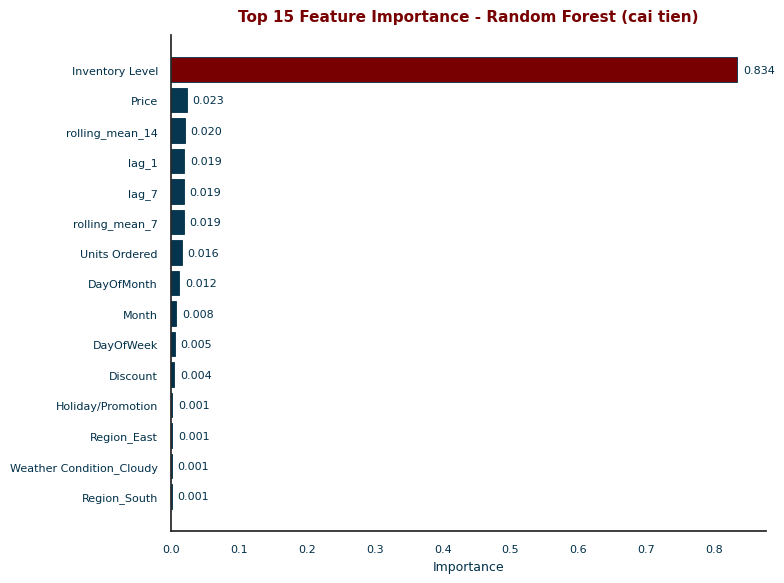

                     feature  importance
17           Inventory Level    0.834315
18                     Price    0.022629
29           rolling_mean_14    0.019644
26                     lag_1    0.019392
27                     lag_7    0.018830
28            rolling_mean_7    0.018823
21             Units Ordered    0.016024
25                DayOfMonth    0.011762
23                     Month    0.007690
22                 DayOfWeek    0.005096
19                  Discount    0.004460
20         Holiday/Promotion    0.001366
5                Region_East    0.001345
9   Weather Condition_Cloudy    0.001274
7               Region_South    0.001255


In [57]:
# FEATURE IMPORTANCE
feature_names = list(_transformed.columns) + [
    'Inventory Level', 'Price', 'Discount', 'Holiday/Promotion', 'Units Ordered',
    'DayOfWeek', 'Month', 'IsWeekend', 'DayOfMonth',
    'lag_1', 'lag_7', 'rolling_mean_7', 'rolling_mean_14'
]

importances = pd.DataFrame({
    'feature': feature_names,
    'importance': rf_model.feature_importances_
}).sort_values('importance', ascending=False)

palette = {
    "red_dark": "#780000",
    "red": "#C1121F",
    "cream": "#FDF0D5",
    "navy": "#003049",
    "blue": "#669BBC",
}

sns.set_theme(style="white", font="DejaVu Sans")

# Lay top 15, dao nguoc de feature quan trong nhat nam tren cung
top15 = importances.head(15).iloc[::-1]

# Gradient mau theo do quan trong: navy (thap nhat) -> red dark (cao nhat)
cmap = LinearSegmentedColormap.from_list(
    "fire_ice", [palette["navy"], palette["blue"], palette["red"], palette["red_dark"]]
)
norm_importance = (top15['importance'] - top15['importance'].min()) / \
                   (top15['importance'].max() - top15['importance'].min())
bar_colors = [cmap(v) for v in norm_importance]

fig, ax = plt.subplots(figsize=(8, 6))   # kich thuoc nho lai
fig.patch.set_facecolor("white")
ax.set_facecolor("white")

bars = ax.barh(top15['feature'], top15['importance'], color=bar_colors,
                edgecolor=palette["navy"], linewidth=0.6)

# Ghi gia tri importance ngay canh moi thanh
for bar, val in zip(bars, top15['importance']):
    ax.text(bar.get_width() + top15['importance'].max() * 0.01,
             bar.get_y() + bar.get_height() / 2,
             f"{val:.3f}", va="center", fontsize=8, color=palette["navy"])

ax.set_xlabel('Importance', fontsize=9, color=palette["navy"])
ax.set_title('Top 15 Feature Importance - Random Forest (cai tien)',
             fontsize=11, fontweight="bold", color=palette["red_dark"], pad=10)
ax.tick_params(labelsize=8, colors=palette["navy"])
sns.despine(ax=ax)

plt.tight_layout()
plt.show()

print(importances.head(15))

In [58]:
# RF GỐC (KHÔNG có lag/date) - chia theo cùng mốc thời gian để so sánh công bằng
X_baseline = pd.concat([
    _transformed,
    data[['Inventory Level', 'Price', 'Discount', 'Holiday/Promotion', 'Units Ordered']]
], axis=1)

X_base_train_raw, X_base_test_raw = X_baseline[train_mask], X_baseline[test_mask]

scaler_base = StandardScaler()
X_base_train = scaler_base.fit_transform(X_base_train_raw)
X_base_test = scaler_base.transform(X_base_test_raw)

rf_baseline = RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42)
rf_baseline.fit(X_base_train, y_train)

y_pred_base_test = rf_baseline.predict(X_base_test)

r2_base = r2_score(y_test, y_pred_base_test)
mae_base = mean_absolute_error(y_test, y_pred_base_test)
rmse_base = np.sqrt(mean_squared_error(y_test, y_pred_base_test))

# BẢNG SO SÁNH
comparison = pd.DataFrame({
    'Model': ['RF - Baseline (không lag/date)', 'RF - Cải tiến (có lag/date)'],
    'R2': [r2_base, r2_test],
    'MAE': [mae_base, mae_test],
    'RMSE': [rmse_base, rmse_test]
})

print(comparison)

                            Model        R2        MAE       RMSE
0  RF - Baseline (không lag/date)  0.338608  68.900126  88.014209
1     RF - Cải tiến (có lag/date)  0.338722  68.884329  88.006609


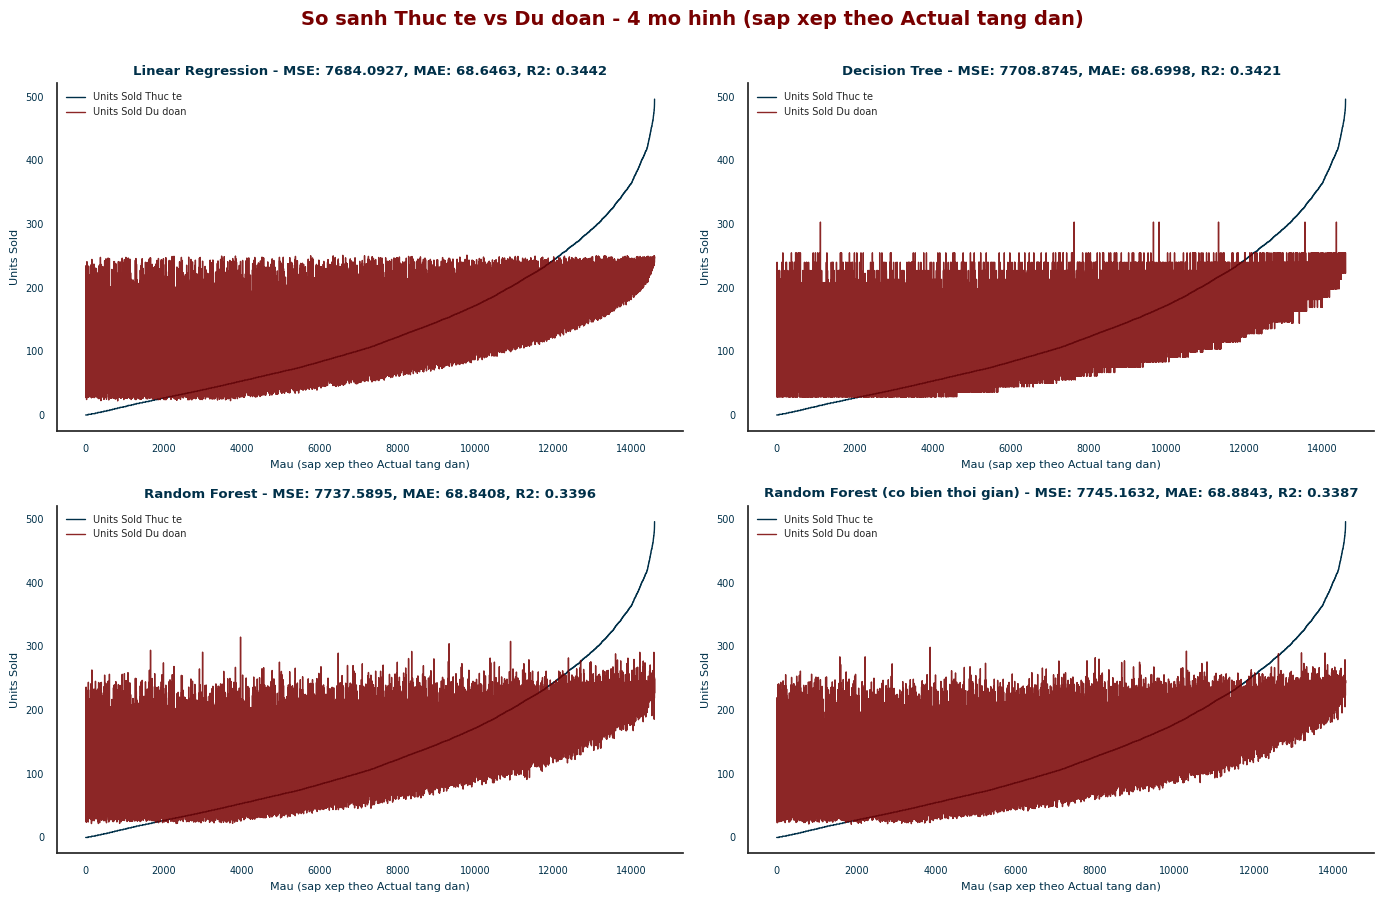

In [59]:
# Chart tong hop: Thuc te vs Du doan cho 4 model (khong bao gom SARIMAX), ve chung 1 hinh
# Sap xep theo Actual tang dan de de nhin xu huong khop nhau giua 2 duong
# (LR/DT/RF ban goc dung tap test chia random nen khong theo thu tu thoi gian,
# RF co bien thoi gian dung tap test chia theo thoi gian)

model_order = [
    "Linear Regression",
    "Decision Tree",
    "Random Forest",
    "Random Forest (co bien thoi gian)",
]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
fig.patch.set_facecolor("white")
fig.suptitle("So sanh Thuc te vs Du doan - 4 mo hinh (sap xep theo Actual tang dan)",
             fontsize=14, fontweight="bold", color=palette["red_dark"], y=1.0)

axes_flat = axes.flatten()

for ax, model_name in zip(axes_flat, model_order):
    ax.set_facecolor("white")

    if model_name not in actual_vs_predicted_data:
        ax.axis("off")
        ax.text(0.5, 0.5, f"Chua co du lieu\ncho {model_name}\n(chua chay cell tuong ung)",
                ha="center", va="center", fontsize=9, color=palette["red_dark"])
        continue

    y_true, y_pred = actual_vs_predicted_data[model_name]
    order_idx = np.argsort(y_true)
    y_true_sorted = y_true[order_idx]
    y_pred_sorted = y_pred[order_idx]

    mse = mean_squared_error(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)

    ax.plot(range(len(y_true_sorted)), y_true_sorted, color=palette["navy"],
            linewidth=1, label="Units Sold Thuc te")
    ax.plot(range(len(y_pred_sorted)), y_pred_sorted, color=palette["red_dark"],
            linewidth=1, alpha=0.85, label="Units Sold Du doan")

    ax.set_title(f"{model_name} - MSE: {mse:.4f}, MAE: {mae:.4f}, R2: {r2:.4f}",
                 fontsize=9.5, fontweight="bold", color=palette["navy"])
    ax.set_xlabel("Mau (sap xep theo Actual tang dan)", fontsize=8, color=palette["navy"])
    ax.set_ylabel("Units Sold", fontsize=8, color=palette["navy"])
    ax.tick_params(labelsize=7, colors=palette["navy"])
    ax.legend(fontsize=7, frameon=False, loc="upper left")
    sns.despine(ax=ax)

plt.tight_layout()
plt.show()

##3.4 Mô hình Time series

# **SARIMAX**



In [60]:
!pip install pmdarima

In [61]:
#IMPORTS & UTILITY FUNCTIONS

def calculate_mape(y_true, y_pred):
    # Calculate MAPE, loai gia tri 0
    mask = y_true != 0
    if mask.sum() == 0:
        return np.nan
    return np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100


def calculate_mase(y_true, y_pred, y_train):
    # Calculate MASE (Mean Absolute Scaled Error)
    n = len(y_train)
    d = np.sum(np.abs(np.diff(y_train))) / (n - 1)
    mae = np.mean(np.abs(y_true - y_pred))
    return mae / d if d != 0 else np.nan


def get_naive_baseline(y_train, y_test):
    # Naive forecast: gia tri cuoi cung
    last_value = y_train.iloc[-1]
    return np.full(len(y_test), last_value)


def get_seasonal_naive_baseline(y_train, y_test, season=7):
    # Seasonal naive: gia tri cung ngay tuan truoc
    pred = []
    for i in range(len(y_test)):
        idx = len(y_train) - season + (i % season)
        if idx >= 0 and idx < len(y_train):
            pred.append(y_train.iloc[idx])
        else:
            pred.append(y_train.iloc[-1])
    return np.array(pred)


def ljung_box_test(residuals, lags=10):
    # Ljung-Box test cho tu tuong quan (khong in, chi tra ve ket qua)
    try:
        lb_test = acorr_ljungbox(residuals, lags=lags, return_df=True)
        p_values = lb_test["lb_pvalue"].values
        significant = (p_values < 0.05).any()
        return p_values, significant
    except Exception:
        return None, None


def jarque_bera_test(residuals):
    # Jarque-Bera test cho tinh chuan (khong in, chi tra ve ket qua)
    try:
        stat, p_value = jarque_bera(residuals)
        normal = p_value > 0.05
        return p_value, normal
    except Exception:
        return None, None

In [62]:
#DATA PREPARATION
df["Date"] = pd.to_datetime(df["Date"])

results = []

stores = sorted(df["Store ID"].unique())
products = sorted(df["Product ID"].unique())

print("=" * 90)
print("SARIMAX MODEL FOR EACH STORE-PRODUCT COMBINATION")
print(f"Stores: {len(stores)} | Products per store: {len(products)}")
print(f"Total models to train: {len(stores) * len(products)}")
print("=" * 90)

SARIMAX MODEL FOR EACH STORE-PRODUCT COMBINATION
Stores: 5 | Products per store: 20
Total models to train: 100


In [63]:
PLOT_TARGETS = [("S005", "P0015"), ("S003", "P0003")]
dashboard_data = {}

In [64]:
#TRAIN LOOP - CHAY TOAN BO STORE-PRODUCT
for store in stores:
    for product in products:

        # --- Filter sx_data ---
        ts = (
            df[(df["Store ID"] == store) & (df["Product ID"] == product)]
            .sort_values("Date")
            .set_index("Date")
        )

        if len(ts) < 60:
            continue

        # --- Encode categorical ---
        ts["Weather Condition"] = ts["Weather Condition"].astype("category").cat.codes
        ts["Seasonality"] = ts["Seasonality"].astype("category").cat.codes

        # --- Target & exogenous variables ---
        y = ts["Units Sold"]

        X = pd.DataFrame(index=ts.index)
        X["Inventory"] = ts["Inventory Level"]
        X["Units Ordered"] = ts["Units Ordered"]
        X["Price"] = ts["Price"]
        X["Discount"] = ts["Discount"]
        X["Promotion"] = ts["Holiday/Promotion"]
        X["Competitor Price"] = ts["Competitor Pricing"]
        X["Weather"] = ts["Weather Condition"]
        X["Seasonality"] = ts["Seasonality"]

        # Calendar features
        X["DayOfWeek"] = ts.index.dayofweek
        X["Month"] = ts.index.month
        X["Weekend"] = (ts.index.dayofweek >= 5).astype(int)

        # Lag features
        X["Lag1"] = y.shift(1)
        X["Lag7"] = y.shift(7)
        X["MA7"] = y.shift(1).rolling(7).mean()
        X["MA14"] = y.shift(1).rolling(14).mean()

        sx_data = pd.concat([y, X], axis=1).dropna()

        if len(sx_data) < 50:
            continue

        y = sx_data["Units Sold"]
        X = sx_data.drop(columns="Units Sold")

        # --- Train-test split 80-20 ---
        split = int(len(sx_data) * 0.8)
        train_y, test_y = y.iloc[:split], y.iloc[split:]
        train_X, test_X = X.iloc[:split], X.iloc[split:]

        # --- Feature scaling ---
        scaler = StandardScaler()
        train_X_scaled = pd.DataFrame(
            scaler.fit_transform(train_X), columns=train_X.columns, index=train_X.index
        )
        test_X_scaled = pd.DataFrame(
            scaler.transform(test_X), columns=test_X.columns, index=test_X.index
        )

        try:
            # --- auto_arima: tim tham so + ADF test ---
            model = auto_arima(
                train_y,
                X=train_X_scaled,
                start_p=0, start_q=0, max_p=5, max_q=5,
                d=None, D=None,
                seasonal=True, m=7,
                start_P=0, start_Q=0, max_P=2, max_Q=2,
                test="adf",
                information_criterion="aic",
                trace=False,
                stepwise=True,
                suppress_warnings=True,
                error_action="ignore",
            )

            order = model.order
            seasonal_order = model.seasonal_order
            d, D = order[1], seasonal_order[1]

            # --- Print: ADF / Stationarity test ---
            # print(f"\nSTORE {store} | PRODUCT {product}")
            # print("  ADF Test (Stationarity via auto_arima)")
            # print(f"    Order (p,d,q): {order}")
            # print(f"    Seasonal Order (P,D,Q,s): {seasonal_order}")
            # print(f"    Differencing: d={d}, D={D}")

            # --- Predictions ---
            pred = model.predict(n_periods=len(test_y), X=test_X_scaled)

            # --- Accuracy metrics (tinh, khong in - dua vao All Results / Summary) ---
            mae = mean_absolute_error(test_y, pred)
            rmse = np.sqrt(mean_squared_error(test_y, pred))
            mape = calculate_mape(test_y, pred)
            mase = calculate_mase(test_y, pred, train_y)
            r2 = r2_score(test_y, pred)

            # --- Residual diagnostics (tinh, khong in) ---
            residuals = test_y.values - pred
            lb_pvalues, lb_significant = ljung_box_test(residuals)
            jb_pvalue, jb_normal = jarque_bera_test(residuals)
            diagnostics_pass = (
                (not lb_significant if lb_significant is not None else True)
                and (jb_normal if jb_normal is not None else True)
            )

            # --- Baseline comparison ---
            naive_pred = get_naive_baseline(train_y, test_y)
            naive_mae = mean_absolute_error(test_y, naive_pred)
            naive_rmse = np.sqrt(mean_squared_error(test_y, naive_pred))

            seasonal_naive_pred = get_seasonal_naive_baseline(train_y, test_y, season=7)
            seasonal_naive_mae = mean_absolute_error(test_y, seasonal_naive_pred)
            seasonal_naive_rmse = np.sqrt(mean_squared_error(test_y, seasonal_naive_pred))

            improvement_naive = ((naive_mae - mae) / naive_mae * 100) if naive_mae > 0 else 0
            improvement_seasonal = (
                (seasonal_naive_mae - mae) / seasonal_naive_mae * 100
            ) if seasonal_naive_mae > 0 else 0

            # --- Print: Baseline comparison ---
            # print("  Baseline Comparison")
            # print(f"    Naive       - MAE: {naive_mae:.2f} | RMSE: {naive_rmse:.2f}")
            # print(f"    Seasonal Naive - MAE: {seasonal_naive_mae:.2f} | RMSE: {seasonal_naive_rmse:.2f}")
            # print(f"    SARIMAX vs Naive: {improvement_naive:+.2f}%")
            # print(f"    SARIMAX vs Seasonal Naive: {improvement_seasonal:+.2f}%")

            if (store, product) in PLOT_TARGETS:
                dashboard_data[(store, product)] = {
                    "train_y": train_y,
                    "test_y": test_y,
                    "pred": pred,
                    "naive_pred": naive_pred,
                    "seasonal_naive_pred": seasonal_naive_pred,
                    "mae": mae,
                    "rmse": rmse,
                    "r2": r2,
                }

            # --- Save results ---
            results.append({
                "Store": store,
                "Product": product,
                "Order": str(order),
                "Seasonal_Order": str(seasonal_order),
                "d": d,
                "D": D,
                "AIC": model.aic(),
                "BIC": model.bic(),
                "MAE": mae,
                "RMSE": rmse,
                "MAPE": mape,
                "MASE": mase,
                "R2": r2,
                "Ljung_Box_Significant": lb_significant,
                "Jarque_Bera_Normal": jb_normal,
                "Diagnostics_Pass": diagnostics_pass,
                "Naive_MAE": naive_mae,
                "Seasonal_Naive_MAE": seasonal_naive_mae,
                "Improvement_vs_Naive": improvement_naive,
                "Improvement_vs_Seasonal_Naive": improvement_seasonal,
                "Data_Points": len(sx_data),
                "Train_Size": len(train_y),
                "Test_Size": len(test_y),
                "Features": len(X.columns),
            })

        except Exception as e:
            print(f"\nSTORE {store} | PRODUCT {product} - Error: {str(e)[:100]}")
            continue

In [65]:
#ALL RESULTS TABLE
print("\n" + "=" * 90)
print("ALL RESULTS")
print("=" * 90)

if not results:
    print("No successful models trained.")
else:
    results_df = pd.DataFrame(results)
    print(results_df.to_string(index=False))


ALL RESULTS
Store Product     Order Seasonal_Order  d  D         AIC         BIC       MAE      RMSE       MAPE     MASE       R2  Ljung_Box_Significant  Jarque_Bera_Normal  Diagnostics_Pass  Naive_MAE  Seasonal_Naive_MAE  Improvement_vs_Naive  Improvement_vs_Seasonal_Naive  Data_Points  Train_Size  Test_Size  Features
 S001   P0001 (0, 0, 0)   (0, 0, 0, 7)  0  0 6771.229021 6845.194078 70.537561 87.760048 163.555075 0.581879 0.315911                  False                True              True 100.736111          160.256944             29.977879                      55.984708          717         573        144        15
 S001   P0002 (0, 0, 0)   (0, 0, 0, 7)  0  0 6741.874320 6815.839377 66.383342 82.187921 327.827245 0.597926 0.278938                   True                True             False 111.368056          121.298611             40.392833                      45.272793          717         573        144        15
 S001   P0003 (0, 0, 0)   (0, 0, 0, 7)  0  0 6725.233504 679

In [66]:
#SUMMARY STATISTICS
total_combinations = df[["Store ID", "Product ID"]].drop_duplicates().shape[0]

if results:
    print("\n" + "=" * 90)
    print("SUMMARY STATISTICS")
    print("=" * 90)

    print(f"\nModels Trained: {len(results_df)} / {total_combinations}")
    print(f"Success Rate: {len(results_df) / total_combinations * 100:.1f}%")

    print("\nAccuracy Metrics (Average):")
    print(f"  MAE:  {results_df['MAE'].mean():.2f} units (+/-{results_df['MAE'].std():.2f})")
    print(f"  RMSE: {results_df['RMSE'].mean():.2f} units (+/-{results_df['RMSE'].std():.2f})")
    print(f"  MAPE: {results_df['MAPE'].mean():.2f}% (+/-{results_df['MAPE'].std():.2f}%)")
    print(f"  MASE: {results_df['MASE'].mean():.4f} (+/-{results_df['MASE'].std():.4f})")
    print(f"  R2:   {results_df['R2'].mean():.4f} (+/-{results_df['R2'].std():.4f})")

    print("\nDiagnostic Tests:")
    diagnostics_pass_count = results_df["Diagnostics_Pass"].sum()
    print(f"  Models Passing Diagnostics: {diagnostics_pass_count} / {len(results_df)} "
          f"({diagnostics_pass_count / len(results_df) * 100:.1f}%)")

    ljung_box_fail = results_df["Ljung_Box_Significant"].sum()
    print(f"  Ljung-Box Test Failures: {ljung_box_fail} ({ljung_box_fail / len(results_df) * 100:.1f}%)")

    jb_fail = (~results_df["Jarque_Bera_Normal"]).sum()
    print(f"  Jarque-Bera Test Failures: {jb_fail} ({jb_fail / len(results_df) * 100:.1f}%)")

    print("\nBaseline Comparison:")
    improvement_naive_mean = results_df["Improvement_vs_Naive"].mean()
    improvement_seasonal_mean = results_df["Improvement_vs_Seasonal_Naive"].mean()
    print(f"  Average Improvement vs Naive: {improvement_naive_mean:+.2f}%")
    print(f"  Average Improvement vs Seasonal Naive: {improvement_seasonal_mean:+.2f}%")

    better_than_naive = (results_df["Improvement_vs_Naive"] > 0).sum()
    print(f"  Models Better than Naive: {better_than_naive} / {len(results_df)} "
          f"({better_than_naive / len(results_df) * 100:.1f}%)")

    better_than_seasonal = (results_df["Improvement_vs_Seasonal_Naive"] > 0).sum()
    print(f"  Models Better than Seasonal Naive: {better_than_seasonal} / {len(results_df)} "
          f"({better_than_seasonal / len(results_df) * 100:.1f}%)")

    print("\n" + "=" * 90)


SUMMARY STATISTICS

Models Trained: 100 / 100
Success Rate: 100.0%

Accuracy Metrics (Average):
  MAE:  70.03 units (+/-4.49)
  RMSE: 88.98 units (+/-5.19)
  MAPE: 251.78% (+/-102.50%)
  MASE: 0.5838 (+/-0.0433)
  R2:   0.3101 (+/-0.0838)

Diagnostic Tests:
  Models Passing Diagnostics: 79 / 100 (79.0%)
  Ljung-Box Test Failures: 20 (20.0%)
  Jarque-Bera Test Failures: 2 (2.0%)

Baseline Comparison:
  Average Improvement vs Naive: +35.70%
  Average Improvement vs Seasonal Naive: +41.26%
  Models Better than Naive: 100 / 100 (100.0%)
  Models Better than Seasonal Naive: 100 / 100 (100.0%)



In [67]:
palette = {
    "red_dark": "#780000",
    "red": "#C1121F",
    "cream": "#FDF0D5",
    "navy": "#003049",
    "blue": "#669BBC",
}

def plot_sarimax_dashboard(store, product, train_y, test_y, pred,
                            naive_pred, seasonal_naive_pred,
                            mae, rmse, r2):
    """Dashboard 3 panel: Time series forecast, Residuals, Actual vs Predicted"""

    residuals = test_y.values - pred

    fig = plt.figure(figsize=(13, 9))
    fig.patch.set_facecolor("white")
    gs = GridSpec(2, 2, height_ratios=[1.3, 1], hspace=0.35, wspace=0.25)

    fig.suptitle(f"SARIMAX Forecast Dashboard - Store {store} | Product {product}",
                 fontsize=14, fontweight="bold", color=palette["navy"], y=0.98)

    # --- Panel 1: Time series forecast (full width) ---
    ax1 = fig.add_subplot(gs[0, :])
    ax1.plot(train_y.index, train_y.values, color="lightgray", marker="o",
              markersize=2, linewidth=0.8, label="Train Data")
    ax1.plot(test_y.index, test_y.values, color=palette["navy"], marker="o",
              markersize=3, linewidth=1.5, label="Actual (Test)")
    ax1.plot(test_y.index, pred, color=palette["red_dark"], marker="s",
              markersize=3, linewidth=1.5, linestyle="--", label="SARIMAX Forecast")
    ax1.plot(test_y.index, naive_pred, color=palette["blue"], marker="^",
              markersize=3, linewidth=1, linestyle="--", label="Naive Baseline")
    ax1.plot(test_y.index, seasonal_naive_pred, color=palette["red"], marker="v",
              markersize=3, linewidth=1, linestyle="--", label="Seasonal Naive")

    ax1.set_title(f"Store {store} | Product {product} - Time Series Forecast",
                   fontsize=11, fontweight="bold", color=palette["navy"])
    ax1.set_xlabel("Date", fontsize=9, color=palette["navy"])
    ax1.set_ylabel("Units Sold", fontsize=9, color=palette["navy"])
    ax1.legend(fontsize=8, ncol=5, loc="upper left", frameon=False)
    ax1.tick_params(labelsize=8, colors=palette["navy"])
    ax1.set_facecolor("white")
    ax1.grid(alpha=0.3)
    sns.despine(ax=ax1)

    # --- Panel 2: Residuals over time ---
    ax2 = fig.add_subplot(gs[1, 0])
    ax2.plot(test_y.index, residuals, color=palette["red_dark"], marker="o",
              markersize=3, linewidth=1)
    ax2.fill_between(test_y.index, residuals, 0, color=palette["red"], alpha=0.3)
    ax2.axhline(0, color="black", linestyle="--", linewidth=1)
    ax2.axhline(residuals.mean() + residuals.std(), color=palette["red_dark"],
                 linestyle=":", linewidth=1, alpha=0.6)
    ax2.axhline(residuals.mean() - residuals.std(), color=palette["red_dark"],
                 linestyle=":", linewidth=1, alpha=0.6)
    ax2.set_title("Residuals Over Time", fontsize=11, fontweight="bold", color=palette["navy"])
    ax2.set_xlabel("Date", fontsize=9, color=palette["navy"])
    ax2.set_ylabel("Residual", fontsize=9, color=palette["navy"])
    ax2.tick_params(labelsize=7, colors=palette["navy"], rotation=30)
    ax2.set_facecolor("white")
    ax2.grid(alpha=0.3)
    sns.despine(ax=ax2)

    # --- Panel 3: Actual vs Predicted ---
    ax3 = fig.add_subplot(gs[1, 1])
    ax3.scatter(test_y.values, pred, color=palette["blue"], edgecolor=palette["navy"],
                 s=40, alpha=0.7)
    lims = [min(test_y.min(), pred.min()), max(test_y.max(), pred.max())]
    ax3.plot(lims, lims, color=palette["red_dark"], linestyle="--", linewidth=1.5)
    stats_text = f"R2 = {r2:.4f}\nMAE = {mae:.2f}\nRMSE = {rmse:.2f}"
    ax3.text(0.05, 0.95, stats_text, transform=ax3.transAxes, fontsize=9,
              verticalalignment="top", color=palette["navy"],
              bbox=dict(boxstyle="round", facecolor=palette["cream"], edgecolor=palette["navy"]))
    ax3.set_title("Actual vs Predicted", fontsize=11, fontweight="bold", color=palette["navy"])
    ax3.set_xlabel("Actual", fontsize=9, color=palette["navy"])
    ax3.set_ylabel("Predicted", fontsize=9, color=palette["navy"])
    ax3.tick_params(labelsize=8, colors=palette["navy"])
    ax3.set_facecolor("white")
    ax3.grid(alpha=0.3)
    sns.despine(ax=ax3)

    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

/tmp/ipykernel_570/1803868172.py:82: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.96])


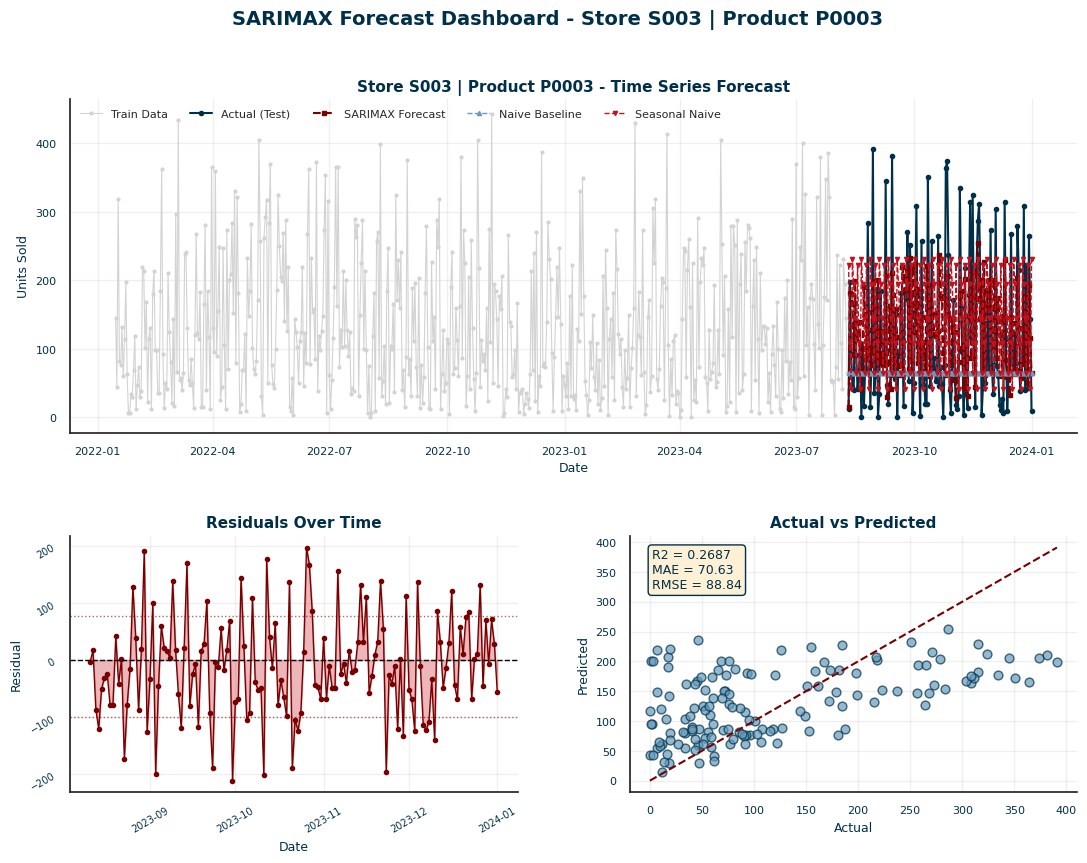

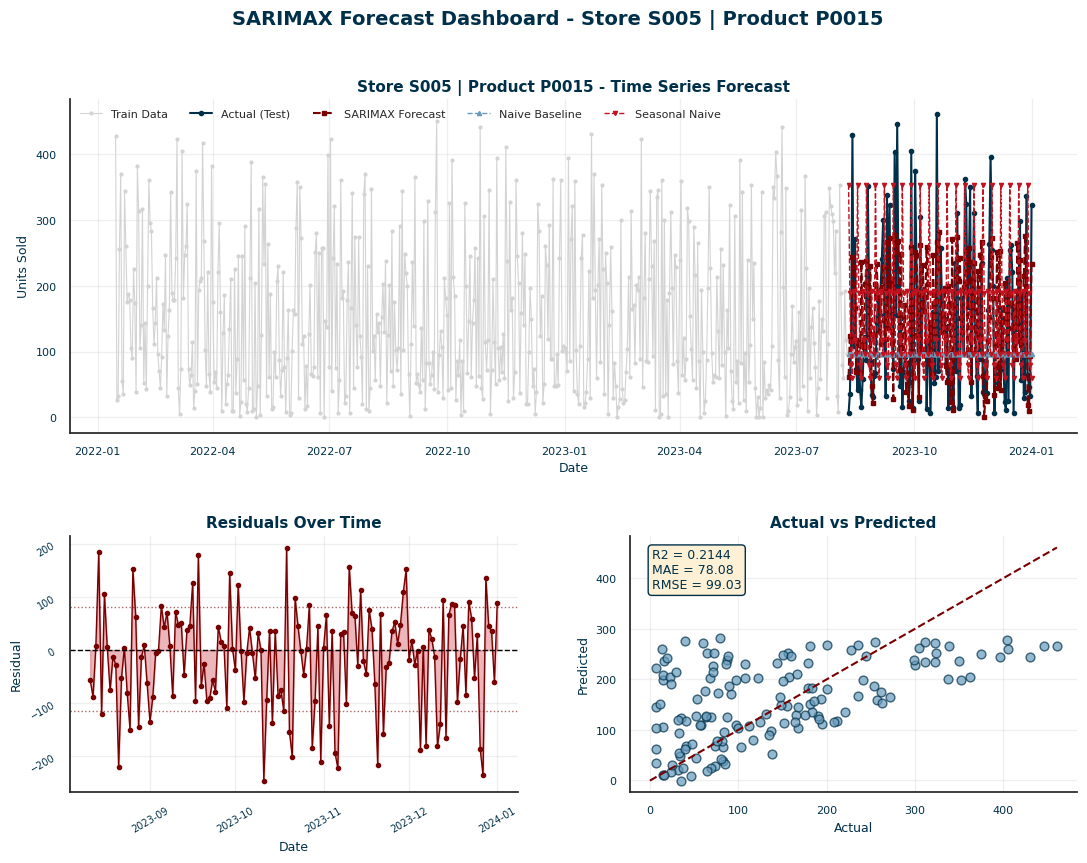

In [68]:
# VE DASHBOARD - chay sau khi CELL 3 da train xong
for (store, product), d in dashboard_data.items():
    plot_sarimax_dashboard(store, product, **d)

#4. So sánh tổng thể 5 mô hình và phân tích sâu SARIMAX

In [69]:
# Luu metric trung binh cua SARIMAX (tinh tren toan bo cac SKU da train thanh cong)
model_comparison_data.append({
    "Model": "SARIMAX (avg per-SKU)",
    "MAE": results_df["MAE"].mean(),
    "RMSE": results_df["RMSE"].mean(),
    "R2": results_df["R2"].mean(),
})

comparison_df = pd.DataFrame(model_comparison_data)
print(comparison_df.to_string(index=False))

                            Model       MAE      RMSE       R2
                Linear Regression 68.646252 87.658957 0.344196
                    Decision Tree 68.699781 87.800196 0.342080
                    Random Forest 68.840753 87.963569 0.339630
Random Forest (co bien thoi gian) 68.884329 88.006609 0.338722
            SARIMAX (avg per-SKU) 70.032161 88.977943 0.310084


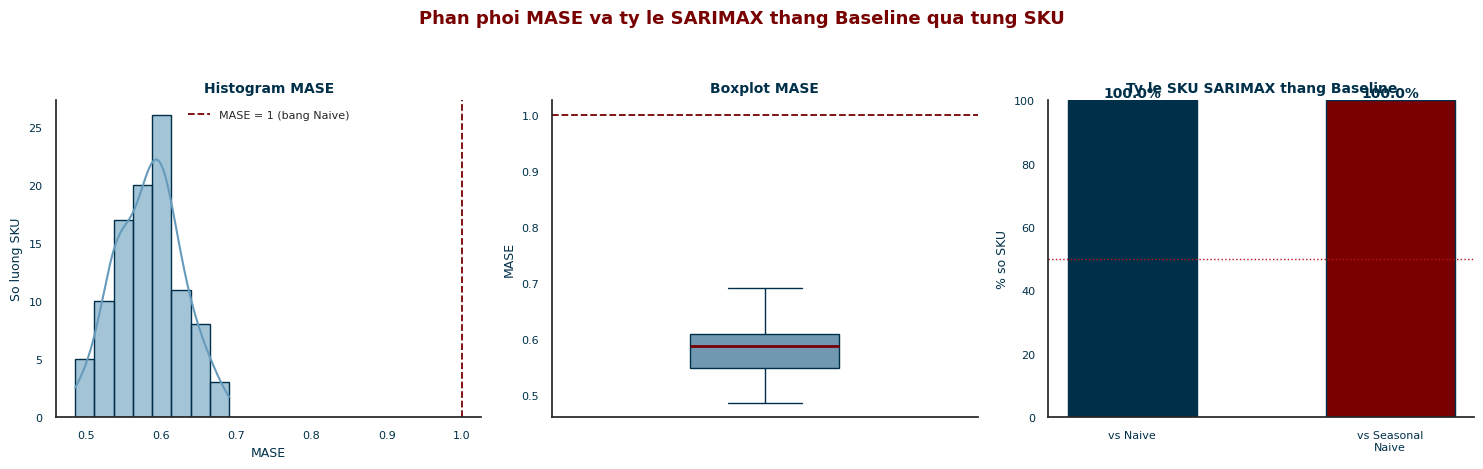

SARIMAX thang Naive Baseline tren 100.0% so SKU (100/100)
SARIMAX thang Seasonal Naive tren 100.0% so SKU (100/100)


In [70]:
# Phan phoi MASE qua tat ca SKU va ty le SARIMAX thang Naive / Seasonal Naive
# Day la bang chung quan trong nhat de danh gia SARIMAX: khong chi nhin R2 trung binh
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
fig.patch.set_facecolor("white")
fig.suptitle("Phan phoi MASE va ty le SARIMAX thang Baseline qua tung SKU",
             fontsize=13, fontweight="bold", color=palette["red_dark"], y=1.04)

# --- Histogram MASE ---
ax = axes[0]
ax.set_facecolor("white")
sns.histplot(results_df["MASE"], kde=True, color=palette["blue"],
             edgecolor=palette["navy"], alpha=0.6, ax=ax)
ax.axvline(1, color=palette["red_dark"], linestyle="--", linewidth=1.3, label="MASE = 1 (bang Naive)")
ax.set_title("Histogram MASE", fontsize=10, fontweight="bold", color=palette["navy"])
ax.set_xlabel("MASE", fontsize=9, color=palette["navy"])
ax.set_ylabel("So luong SKU", fontsize=9, color=palette["navy"])
ax.tick_params(labelsize=8, colors=palette["navy"])
ax.legend(fontsize=8, frameon=False)
sns.despine(ax=ax)

# --- Boxplot MASE ---
ax = axes[1]
ax.set_facecolor("white")
sns.boxplot(y=results_df["MASE"], color=palette["blue"], width=0.35,
            boxprops={"edgecolor": palette["navy"]}, whiskerprops={"color": palette["navy"]},
            capprops={"color": palette["navy"]}, medianprops={"color": palette["red_dark"], "linewidth": 2},
            flierprops={"markerfacecolor": palette["red"], "markeredgecolor": palette["navy"], "alpha": 0.5}, ax=ax)
ax.axhline(1, color=palette["red_dark"], linestyle="--", linewidth=1.3)
ax.set_title("Boxplot MASE", fontsize=10, fontweight="bold", color=palette["navy"])
ax.set_ylabel("MASE", fontsize=9, color=palette["navy"])
ax.tick_params(labelsize=8, colors=palette["navy"])
sns.despine(ax=ax)

# --- Ty le SKU SARIMAX thang Baseline ---
ax = axes[2]
ax.set_facecolor("white")
pct_beat_naive = (results_df["Improvement_vs_Naive"] > 0).mean() * 100
pct_beat_seasonal = (results_df["Improvement_vs_Seasonal_Naive"] > 0).mean() * 100
bars = ax.bar(["vs Naive", "vs Seasonal\nNaive"], [pct_beat_naive, pct_beat_seasonal],
              color=[palette["navy"], palette["red_dark"]], edgecolor=palette["navy"], width=0.5)
for bar, val in zip(bars, [pct_beat_naive, pct_beat_seasonal]):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), f"{val:.1f}%",
            ha="center", va="bottom", fontsize=10, fontweight="bold", color=palette["navy"])
ax.axhline(50, color=palette["red"], linestyle=":", linewidth=1)
ax.set_ylim(0, 100)
ax.set_title("Ty le SKU SARIMAX thang Baseline", fontsize=10, fontweight="bold", color=palette["navy"])
ax.set_ylabel("% so SKU", fontsize=9, color=palette["navy"])
ax.tick_params(labelsize=8, colors=palette["navy"])
sns.despine(ax=ax)

plt.tight_layout()
plt.show()

print(f"SARIMAX thang Naive Baseline tren {pct_beat_naive:.1f}% so SKU "
      f"({int((results_df['Improvement_vs_Naive']>0).sum())}/{len(results_df)})")
print(f"SARIMAX thang Seasonal Naive tren {pct_beat_seasonal:.1f}% so SKU "
      f"({int((results_df['Improvement_vs_Seasonal_Naive']>0).sum())}/{len(results_df)})")

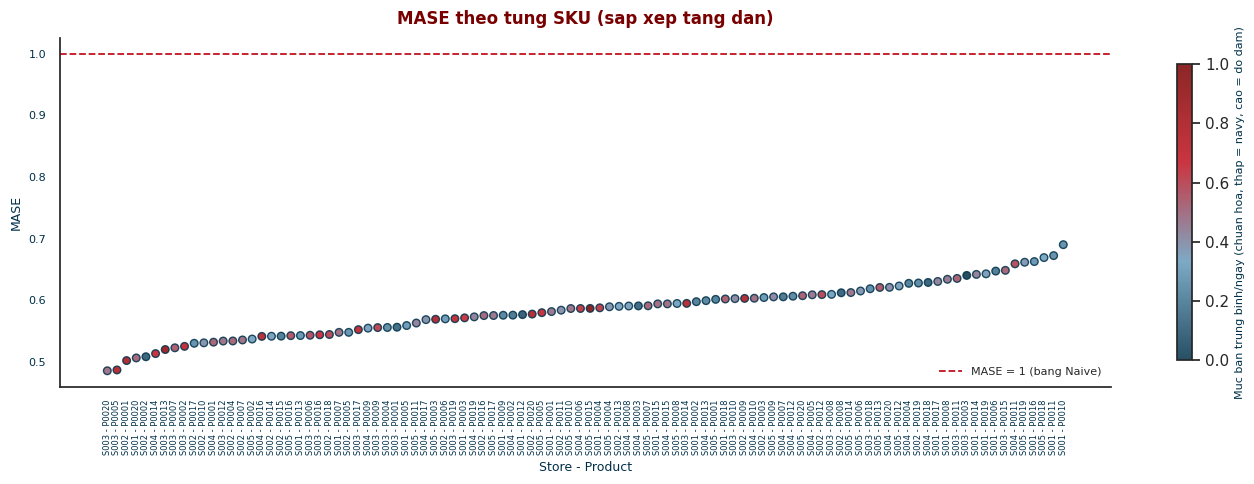

In [71]:
# Scatter MASE theo tung SKU - to mau theo muc ban trung binh/ngay de kiem tra
# SARIMAX co chuyen biet tot hon o nhom SKU ban chay/on dinh hay khong (so voi SKU ban cham, nhieu)
plot_df = results_df.merge(
    sp.rename(columns={"Store ID": "Store", "Product ID": "Product"}),
    on=["Store", "Product"], how="left",
)
plot_df["SKU"] = plot_df["Store"] + " - " + plot_df["Product"]
plot_df = plot_df.sort_values("MASE").reset_index(drop=True)

cmap = LinearSegmentedColormap.from_list(
    "fire_ice", [palette["navy"], palette["blue"], palette["red"], palette["red_dark"]]
)
norm_avg = (plot_df["avg"] - plot_df["avg"].min()) / (plot_df["avg"].max() - plot_df["avg"].min() + 1e-9)

fig, ax = plt.subplots(figsize=(14, 5))
fig.patch.set_facecolor("white")
ax.set_facecolor("white")

sc = ax.scatter(range(len(plot_df)), plot_df["MASE"], c=norm_avg, cmap=cmap,
                 edgecolor=palette["navy"], s=30, alpha=0.85)
ax.axhline(1, color=palette["red"], linestyle="--", linewidth=1.3, label="MASE = 1 (bang Naive)")

cbar = plt.colorbar(sc, ax=ax, shrink=0.85)
cbar.set_label("Muc ban trung binh/ngay (chuan hoa, thap = navy, cao = do dam)",
               fontsize=8, color=palette["navy"])

ax.set_xticks(range(len(plot_df)))
ax.set_xticklabels(plot_df["SKU"], rotation=90, fontsize=6, color=palette["navy"])
ax.set_title("MASE theo tung SKU (sap xep tang dan)", fontsize=12, fontweight="bold",
             color=palette["red_dark"], pad=10)
ax.set_xlabel("Store - Product", fontsize=9, color=palette["navy"])
ax.set_ylabel("MASE", fontsize=9, color=palette["navy"])
ax.tick_params(axis="y", labelsize=8, colors=palette["navy"])
ax.legend(fontsize=8, frameon=False)
sns.despine(ax=ax)

plt.tight_layout()
plt.show()

/tmp/ipykernel_570/3184798497.py:12: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: np.sqrt(mean_squared_error(g["y_true"], g["y_pred"])) if len(g) >= MIN_TEST_ROWS else np.nan)


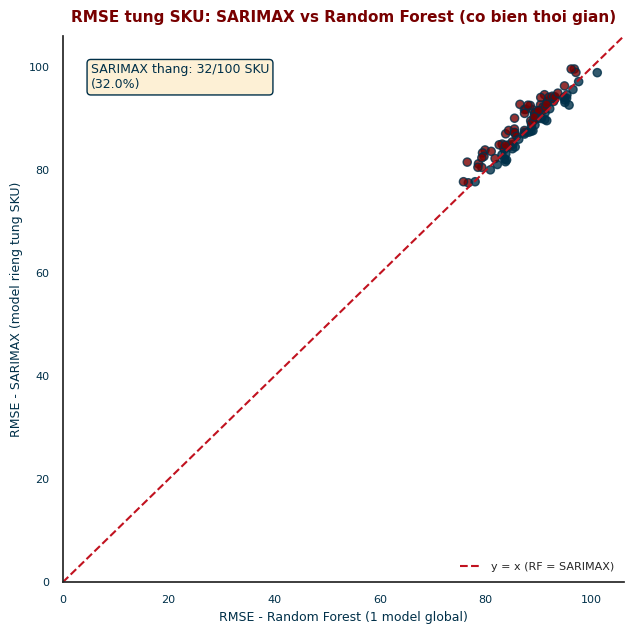

So SKU so sanh duoc (co du du lieu o ca 2 phia): 100 / 100
SARIMAX thang RF tren 32 SKU (32.0%)
RF thang SARIMAX tren 68 SKU (68.0%)


In [72]:
# So sanh RMSE tung SKU: SARIMAX (100 model rieng) vs Random Forest co bien thoi gian (1 model global)
# Tinh lai RMSE cua RF tren tung SKU trong TAP TEST cua chinh no de so sanh cong bang, loai bo
# nhieu do khac cach tong hop/trung binh giua 2 phuong phap
test_info = data.loc[test_mask, ["Store ID", "Product ID"]].copy()
test_info["y_true"] = np.asarray(y_test).ravel()
test_info["y_pred"] = np.asarray(rf_model.predict(X_test)).ravel()

MIN_TEST_ROWS = 5  # SKU can it nhat 5 dong trong tap test moi tinh RMSE co y nghia

rf_rmse_per_sku = (
    test_info.groupby(["Store ID", "Product ID"])
    .apply(lambda g: np.sqrt(mean_squared_error(g["y_true"], g["y_pred"])) if len(g) >= MIN_TEST_ROWS else np.nan)
    .reset_index(name="RF_RMSE")
    .dropna()
)

sarimax_rmse = results_df[["Store", "Product", "RMSE"]].rename(
    columns={"Store": "Store ID", "Product": "Product ID", "RMSE": "SARIMAX_RMSE"}
)

rmse_compare = rf_rmse_per_sku.merge(sarimax_rmse, on=["Store ID", "Product ID"], how="inner")

sarimax_wins = (rmse_compare["SARIMAX_RMSE"] < rmse_compare["RF_RMSE"]).sum()
total_compared = len(rmse_compare)

fig, ax = plt.subplots(figsize=(6.5, 6.5))
fig.patch.set_facecolor("white")
ax.set_facecolor("white")

point_colors = [palette["navy"] if s < r else palette["red_dark"]
                for s, r in zip(rmse_compare["SARIMAX_RMSE"], rmse_compare["RF_RMSE"])]
ax.scatter(rmse_compare["RF_RMSE"], rmse_compare["SARIMAX_RMSE"], color=point_colors,
           edgecolor=palette["navy"], s=35, alpha=0.8)

lims = [0, max(rmse_compare["RF_RMSE"].max(), rmse_compare["SARIMAX_RMSE"].max()) * 1.05]
ax.plot(lims, lims, color=palette["red"], linestyle="--", linewidth=1.5, label="y = x (RF = SARIMAX)")
ax.set_xlim(lims)
ax.set_ylim(lims)

ax.text(0.05, 0.95,
        f"SARIMAX thang: {sarimax_wins}/{total_compared} SKU\n({sarimax_wins / total_compared * 100:.1f}%)",
        transform=ax.transAxes, fontsize=9, va="top", color=palette["navy"],
        bbox=dict(boxstyle="round", facecolor=palette["cream"], edgecolor=palette["navy"]))

ax.set_title("RMSE tung SKU: SARIMAX vs Random Forest (co bien thoi gian)",
             fontsize=11, fontweight="bold", color=palette["red_dark"], pad=10)
ax.set_xlabel("RMSE - Random Forest (1 model global)", fontsize=9, color=palette["navy"])
ax.set_ylabel("RMSE - SARIMAX (model rieng tung SKU)", fontsize=9, color=palette["navy"])
ax.tick_params(labelsize=8, colors=palette["navy"])
ax.legend(fontsize=8, frameon=False, loc="lower right")
sns.despine(ax=ax)

plt.tight_layout()
plt.show()

print(f"So SKU so sanh duoc (co du du lieu o ca 2 phia): {total_compared} / {len(results_df)}")
print(f"SARIMAX thang RF tren {sarimax_wins} SKU ({sarimax_wins / total_compared * 100:.1f}%)")
print(f"RF thang SARIMAX tren {total_compared - sarimax_wins} SKU "
      f"({(total_compared - sarimax_wins) / total_compared * 100:.1f}%)")